In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
!pip install emoji vaderSentiment

import os
import re
import glob
import time
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from tqdm.auto import tqdm

tqdm.pandas()

import emoji

from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS

from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully.")

All libraries imported successfully.


In [ ]:
# ============================================================
# 3. Configuration
# ============================================================

RANDOM_STATE = 42
TEST_SIZE = 0.30

# TF-IDF feature limit
MAX_FEATURES = 5000

# Minimum words after cleaning
MIN_WORDS = 3

# Use all comment files such as GBcomments.csv and UScomments.csv
USE_ALL_COMMENT_FILES = True

# For full dataset, keep None.
# For faster testing, use 50000 or 100000.
MAX_ROWS_PER_FILE = None

# KNN is very slow on large sparse TF-IDF data.
# Recommended: True for comparison, but use a sample.
RUN_KNN = True
KNN_SAMPLE_SIZE = 60000   # Set None to use full binary dataset, but it will be slow.

# Run multiclass experiment with positive, negative, neutral
RUN_MULTICLASS_EXPERIMENT = True

# Run cross-validation on fast models
RUN_CROSS_VALIDATION = True
CV_SAMPLE_SIZE = 100000   # Use sample to keep Colab fast. Set None for full data.

# Output directory
OUTPUT_DIR = "/content/cse477_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Configuration completed.")
print("Output directory:", OUTPUT_DIR)

Configuration completed.
Output directory: /content/cse477_outputs


In [ ]:
# ============================================================
# 4. Helper Function: Time Formatter
# ============================================================

def format_time(seconds):
    """
    Convert seconds into readable time format.
    """
    seconds = float(seconds)

    if seconds < 60:
        return f"{seconds:.2f} seconds"
    elif seconds < 3600:
        return f"{seconds / 60:.2f} minutes"
    else:
        return f"{seconds / 3600:.2f} hours"

In [ ]:
# ============================================================
# 5. Locate Comment Dataset Files
# ============================================================

# Assuming comment CSV files are already present in this directory
dataset_path = '/content/drive/MyDrive/CSE477/project/'

print("Searching for comment files in:", dataset_path)

all_csv_files = glob.glob(os.path.join(dataset_path, "**", "*.csv"), recursive=True)

comment_files = [
    file_path for file_path in all_csv_files
    if os.path.basename(file_path).lower().endswith("comments.csv")
]

gb_files = [
    file_path for file_path in comment_files
    if os.path.basename(file_path).lower() == "gbcomments.csv"
]

if not comment_files:
    raise FileNotFoundError(
        f"No comment CSV files found in the specified directory: {dataset_path}"
    )

if USE_ALL_COMMENT_FILES:
    selected_files = sorted(comment_files)
else:
    selected_files = gb_files if gb_files else [sorted(comment_files)[0]]

print("\nSelected comment files:")
for file_path in selected_files:
    print("-", file_path)

Searching for comment files in: /content/drive/MyDrive/CSE477/project/

Selected comment files:
- /content/drive/MyDrive/CSE477/project/GBcomments.csv


In [ ]:
# ============================================================
# 6. Read Dataset Files Safely
# ============================================================

def read_comment_file(path, max_rows=None):
    """
    Read YouTube comment CSV safely using multiple encoding attempts.
    """
    read_attempts = [
        {"encoding": "utf-8", "engine": "python"},
        {"encoding": "latin1", "engine": "python"},
        {"encoding": "ISO-8859-1", "engine": "python"},
    ]

    last_error = None

    for kwargs in read_attempts:
        try:
            df_temp = pd.read_csv(
                path,
                on_bad_lines="skip",
                nrows=max_rows,
                **kwargs
            )
            return df_temp
        except Exception as e:
            last_error = e

    raise RuntimeError(f"Could not read file: {path}. Last error: {last_error}")


frames = []

print("\nLoading dataset files...")

for file_path in tqdm(selected_files, desc="Loading CSV files"):
    temp_df = read_comment_file(file_path, max_rows=MAX_ROWS_PER_FILE)
    temp_df["source_file"] = os.path.basename(file_path)
    frames.append(temp_df)

df = pd.concat(frames, ignore_index=True)

print("\nRaw combined dataset shape:", df.shape)
print("Dataset columns:")
print(df.columns.tolist())

display(df.head())


Loading dataset files...


Loading CSV files:   0%|          | 0/1 [00:00<?, ?it/s]


Raw combined dataset shape: (718444, 5)
Dataset columns:
['video_id', 'comment_text', 'likes', 'replies', 'source_file']


,video_id,comment_text,likes,replies,source_file
0,jt2OHQh0HoQ,It's more accurate to call it the M+ (1000) be...,0,0,GBcomments.csv
1,jt2OHQh0HoQ,To be there with a samsung phone\n😂😂😂,1,0,GBcomments.csv
2,jt2OHQh0HoQ,"Thank gosh, a place I can watch it without hav...",0,0,GBcomments.csv
3,jt2OHQh0HoQ,What happened to the home button on the iPhone...,0,0,GBcomments.csv
4,jt2OHQh0HoQ,Power is the disease. Care is the cure. Keep...,0,0,GBcomments.csv


In [ ]:
if "comment_text" not in df.columns:
    possible_text_cols = [
        col for col in df.columns
        if "comment" in col.lower() or "text" in col.lower()
    ]

    if possible_text_cols:
        comment_col = possible_text_cols[0]
        print(f"Column 'comment_text' not found. Using detected text column: {comment_col}")
    else:
        raise KeyError(
            "No comment text column found. Expected column name: 'comment_text'. "
            f"Available columns: {df.columns.tolist()}"
        )
else:
    comment_col = "comment_text"

df = df[[comment_col]].rename(columns={comment_col: "comment_text"})

df = df.dropna(subset=["comment_text"])
df["comment_text"] = df["comment_text"].astype(str)

before_duplicates = df.shape[0]
df = df.drop_duplicates(subset=["comment_text"])
after_duplicates = df.shape[0]

df = df.reset_index(drop=True)

print("\nAfter selecting comment text and removing duplicate comments:")
print("Before duplicate removal:", before_duplicates)
print("After duplicate removal:", after_duplicates)
print("Removed duplicates:", before_duplicates - after_duplicates)
print("Current shape:", df.shape)

display(df.head())


After selecting comment text and removing duplicate comments:
Before duplicate removal: 718416
After duplicate removal: 372836
Removed duplicates: 345580
Current shape: (372836, 1)


,comment_text
0,It's more accurate to call it the M+ (1000) be...
1,To be there with a samsung phone\n😂😂😂
2,"Thank gosh, a place I can watch it without hav..."
3,What happened to the home button on the iPhone...
4,Power is the disease. Care is the cure. Keep...


In [ ]:
# ============================================================
# 8. Spam and Noise Filtering
# ============================================================

def is_spam_or_noise(text):
    """
    Detect simple spam/noise patterns in YouTube comments.
    This does not catch all spam, but removes obvious low-quality cases.
    """
    text = str(text).lower().strip()

    # Empty or extremely short comments
    if len(text) == 0:
        return True

    # URL-only or URL-heavy comments
    url_patterns = [
        r"http\S+",
        r"www\S+",
        r"youtu\.be",
        r"youtube\.com"
    ]

    url_count = sum(len(re.findall(pattern, text)) for pattern in url_patterns)

    if url_count > 0:
        return True

    # Common self-promotion / spam phrases
    spam_phrases = [
        "sub to my channel",
        "subscribe me",
        "subscribe to my channel",
        "check out my channel",
        "visit my channel",
        "follow me",
        "free gift",
        "click here",
        "watch my video",
        "my last video",
        "please subscribe",
        "plz subscribe",
        "giveaway"
    ]

    if any(phrase in text for phrase in spam_phrases):
        return True

    # Too few alphabetic characters
    alphabetic_chars = re.findall(r"[a-zA-Z]", text)
    if len(alphabetic_chars) < 3:
        return True

    return False


print("Detecting spam/noise comments...")

df["is_spam_noise"] = df["comment_text"].progress_apply(is_spam_or_noise)

print("\nSpam/noise distribution:")
print(df["is_spam_noise"].value_counts())

before_filter = df.shape[0]
df = df[df["is_spam_noise"] == False].copy()
after_filter = df.shape[0]

df = df.reset_index(drop=True)

print("\nAfter spam/noise filtering:")
print("Before filtering:", before_filter)
print("After filtering:", after_filter)
print("Removed:", before_filter - after_filter)

display(df.head())

Detecting spam/noise comments...


  0%|          | 0/372836 [00:00<?, ?it/s]


Spam/noise distribution:
is_spam_noise
False    360140
True      12696
Name: count, dtype: int64

After spam/noise filtering:
Before filtering: 372836
After filtering: 360140
Removed: 12696


,comment_text,is_spam_noise
0,It's more accurate to call it the M+ (1000) be...,False
1,To be there with a samsung phone\n😂😂😂,False
2,"Thank gosh, a place I can watch it without hav...",False
3,What happened to the home button on the iPhone...,False
4,Power is the disease. Care is the cure. Keep...,False


In [ ]:
# ============================================================
# 9. Text Cleaning for Machine Learning
# ============================================================

def clean_text_for_ml(text):
    """
    Clean text for TF-IDF machine learning.

    Important:
    - This cleaning is for ML feature extraction.
    - VADER sentiment labeling will use raw comment_text separately.
    """
    text = str(text)

    # Convert emojis into text descriptions
    text = emoji.demojize(text, delimiters=(" ", " "))

    # Lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|youtu\.be\S+|youtube\.com\S+", " ", text)

    # Remove HTML entities
    text = re.sub(r"&amp;|&quot;|&#\d+;", " ", text)

    # Expand common contractions lightly
    text = re.sub(r"\bcan't\b", "can not", text)
    text = re.sub(r"\bwon't\b", "will not", text)
    text = re.sub(r"\bn't\b", " not", text)
    text = re.sub(r"\bit's\b", "it is", text)
    text = re.sub(r"\bi'm\b", "i am", text)
    text = re.sub(r"\byou're\b", "you are", text)
    text = re.sub(r"\bthey're\b", "they are", text)
    text = re.sub(r"\bwe're\b", "we are", text)

    # Keep letters and spaces only after emoji conversion
    text = re.sub(r"[^a-zA-Z\s]", " ", text)

    # Normalize repeated spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


print("Cleaning text for machine learning...")

df["clean_text"] = df["comment_text"].progress_apply(clean_text_for_ml)

df = df[df["clean_text"].str.strip() != ""].copy()
df = df.reset_index(drop=True)

df["word_count"] = df["clean_text"].apply(lambda x: len(str(x).split()))

df = df[df["word_count"] >= MIN_WORDS].copy()
df = df.reset_index(drop=True)

print("\nAfter ML text cleaning and minimum word filtering:")
print(df.shape)

display(df[["comment_text", "clean_text", "word_count"]].head(10))

Cleaning text for machine learning...


  0%|          | 0/360140 [00:00<?, ?it/s]


After ML text cleaning and minimum word filtering:
(337850, 4)


,comment_text,clean_text,word_count
0,It's more accurate to call it the M+ (1000) be...,it is more accurate to call it the m because t...,19
1,To be there with a samsung phone\n😂😂😂,to be there with a samsung phone n face with t...,23
2,"Thank gosh, a place I can watch it without hav...",thank gosh a place i can watch it without havi...,20
3,What happened to the home button on the iPhone...,what happened to the home button on the iphone...,14
4,Power is the disease. Care is the cure. Keep...,power is the disease care is the cure keep car...,22
5,Keep calm and buy iphone 8 Keep calm and buy i...,keep calm and buy iphone keep calm and buy iph...,21
6,i am a big fan of youtube and u !!!!!!!!!!!!!,i am a big fan of youtube and u,9
7,You will never find Losers who line up and pay...,you will never find losers who line up and pay...,23
8,"I'm only here to see Emma, I love her so much!...",i am only here to see emma i love her so much ...,18
9,Mom said: Just one more video before bed,mom said just one more video before bed,8


Generating VADER sentiment pseudo-labels from raw comment_text...


  0%|          | 0/337850 [00:00<?, ?it/s]

  0%|          | 0/337850 [00:00<?, ?it/s]


Sentiment distribution:
sentiment
positive    178368
neutral      89600
negative     69882
Name: count, dtype: int64


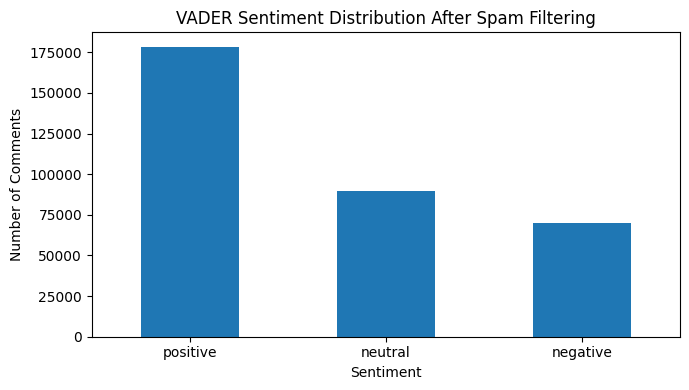

,comment_text,clean_text,vader_score,sentiment
0,It's more accurate to call it the M+ (1000) be...,it is more accurate to call it the m because t...,0.0000,neutral
1,To be there with a samsung phone\n😂😂😂,to be there with a samsung phone n face with t...,0.8271,positive
2,"Thank gosh, a place I can watch it without hav...",thank gosh a place i can watch it without havi...,0.6369,positive
3,What happened to the home button on the iPhone...,what happened to the home button on the iphone...,0.0000,neutral
4,Power is the disease. Care is the cure. Keep...,power is the disease care is the cure keep car...,0.8910,positive
5,Keep calm and buy iphone 8 Keep calm and buy i...,keep calm and buy iphone keep calm and buy iph...,0.7096,positive
6,i am a big fan of youtube and u !!!!!!!!!!!!!,i am a big fan of youtube and u,0.5374,positive
7,You will never find Losers who line up and pay...,you will never find losers who line up and pay...,0.6219,positive
8,"I'm only here to see Emma, I love her so much!...",i am only here to see emma i love her so much ...,0.9149,positive
9,Mom said: Just one more video before bed,mom said just one more video before bed,0.0000,neutral


In [ ]:
# ============================================================
# 10. VADER Sentiment Labeling Using Raw Text
# ============================================================

analyzer = SentimentIntensityAnalyzer()

def get_vader_sentiment_from_raw_text(text):
    """
    Generate sentiment label using VADER on raw comment text.

    Important:
    This is pseudo-labeling, not human annotation.
    """
    score = analyzer.polarity_scores(str(text))["compound"]

    if score >= 0.05:
        return "positive"
    elif score <= -0.05:
        return "negative"
    else:
        return "neutral"


def get_vader_score(text):
    """
    Return VADER compound score.
    """
    return analyzer.polarity_scores(str(text))["compound"]


print("Generating VADER sentiment pseudo-labels from raw comment_text...")

df["vader_score"] = df["comment_text"].progress_apply(get_vader_score)
df["sentiment"] = df["comment_text"].progress_apply(get_vader_sentiment_from_raw_text)

print("\nSentiment distribution:")
print(df["sentiment"].value_counts())

plt.figure(figsize=(7, 4))
df["sentiment"].value_counts().plot(kind="bar")
plt.title("VADER Sentiment Distribution After Spam Filtering")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "sentiment_distribution_after_spam_filtering.png"), dpi=300)
plt.show()

display(df[["comment_text", "clean_text", "vader_score", "sentiment"]].head(10))

In [ ]:
# ============================================================
# 11. Stopword Setup
# ============================================================

# Default English stopwords remove words like "not", which are important for sentiment.
# So we keep negation words.
custom_stop_words = set(ENGLISH_STOP_WORDS) - {
    "not", "no", "nor", "never", "none", "cannot"
}

print("Custom stopword list prepared.")
print("Example: 'not' removed from stopword list?", "not" not in custom_stop_words)

Custom stopword list prepared.
Example: 'not' removed from stopword list? True


In [ ]:
# ============================================================
# 12. General Evaluation Function
# ============================================================

def evaluate_model_with_progress(
    model_name,
    model,
    X_train,
    X_test,
    y_train,
    y_test,
    test_text_df,
    model_index,
    total_models,
    overall_start_time,
    experiment_name,
    save_errors=True
):
    """
    Train, predict, evaluate, save confusion matrix and misclassified examples.
    """

    print("\n" + "=" * 90)
    print(f"[{experiment_name}] Starting Model {model_index}/{total_models}: {model_name}")
    print("=" * 90)

    model_start_time = time.time()

    completed_models = model_index - 1
    elapsed_overall = model_start_time - overall_start_time

    if completed_models > 0:
        avg_time = elapsed_overall / completed_models
        remaining_models = total_models - completed_models
        estimated_remaining = avg_time * remaining_models
        print(f"Overall elapsed time so far: {format_time(elapsed_overall)}")
        print(f"Estimated remaining time: {format_time(estimated_remaining)}")
    else:
        print("Estimated remaining time: Calculating after first model finishes...")

    # Training
    print("\nTraining started...")
    fit_start = time.time()
    model.fit(X_train, y_train)
    fit_end = time.time()
    fit_time = fit_end - fit_start

    print(f"Training completed for {model_name}.")
    print("Training time:", format_time(fit_time))

    # Prediction
    print("\nPrediction started...")
    pred_start = time.time()
    y_pred = model.predict(X_test)
    pred_end = time.time()
    prediction_time = pred_end - pred_start

    print(f"Prediction completed for {model_name}.")
    print("Prediction time:", format_time(prediction_time))

    # Metrics
    print("\nCalculating evaluation metrics...")
    metric_start = time.time()

    acc = accuracy_score(y_test, y_pred)

    prec_weighted = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    rec_weighted = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    f1_weighted = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    prec_macro = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    rec_macro = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    f1_macro = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    metric_end = time.time()
    metric_time = metric_end - metric_start

    total_model_time = fit_time + prediction_time + metric_time

    result_row = {
        "Experiment": experiment_name,
        "Model": model_name,
        "Accuracy": acc,
        "Precision_weighted": prec_weighted,
        "Recall_weighted": rec_weighted,
        "F1_weighted": f1_weighted,
        "Precision_macro": prec_macro,
        "Recall_macro": rec_macro,
        "F1_macro": f1_macro,
        "Training_Time": fit_time,
        "Prediction_Time": prediction_time,
        "Metric_Time": metric_time,
        "Total_Time": total_model_time
    }

    print("Metric calculation completed.")
    print("Metric calculation time:", format_time(metric_time))

    print("\n" + "-" * 90)
    print(f"Result for {model_name}")
    print("-" * 90)
    print("Accuracy:", round(acc, 4))
    print("Weighted Precision:", round(prec_weighted, 4))
    print("Weighted Recall:", round(rec_weighted, 4))
    print("Weighted F1-score:", round(f1_weighted, 4))
    print("Macro F1-score:", round(f1_macro, 4))

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, zero_division=0))

    # Confusion matrix
    labels = sorted(pd.Series(y_test).unique())
    cm = confusion_matrix(y_test, y_pred, labels=labels)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels
    )

    disp.plot(values_format="d")
    plt.title(f"Confusion Matrix - {experiment_name} - {model_name}")
    plt.tight_layout()

    safe_exp = re.sub(r"[^a-zA-Z0-9_]+", "_", experiment_name).strip("_")
    safe_model = re.sub(r"[^a-zA-Z0-9_]+", "_", model_name).strip("_")

    cm_path = os.path.join(
        OUTPUT_DIR,
        f"confusion_matrix_{safe_exp}_{safe_model}.png"
    )

    plt.savefig(cm_path, dpi=300)
    plt.show()

    print("Saved confusion matrix:", cm_path)

    # Save misclassified examples
    if save_errors:
        error_df = test_text_df.copy()
        error_df["true_label"] = list(y_test)
        error_df["predicted_label"] = list(y_pred)
        error_df = error_df[error_df["true_label"] != error_df["predicted_label"]].copy()

        error_path = os.path.join(
            OUTPUT_DIR,
            f"misclassified_examples_{safe_exp}_{safe_model}.csv"
        )

        error_df.to_csv(error_path, index=False)

        print("Misclassified examples saved:", error_path)
        print("Number of misclassified examples:", error_df.shape[0])

        display(error_df.head(10))

    model_end_time = time.time()
    actual_total_time = model_end_time - model_start_time

    print("\n" + "-" * 90)
    print(f"Completed Model {model_index}/{total_models}: {model_name}")
    print("Actual total time:", format_time(actual_total_time))
    print("-" * 90)

    return result_row, y_pred, model

In [ ]:
# ============================================================
# 13. Experiment Runner Function
# ============================================================

def run_experiment(
    df_experiment,
    experiment_name,
    label_col="sentiment",
    include_knn=False,
    knn_sample_size=60000
):
    """
    Run TF-IDF + model comparison experiment.
    TF-IDF is fitted only on training data to avoid data leakage.
    """

    print("\n" + "#" * 100)
    print(f"Running Experiment: {experiment_name}")
    print("#" * 100)

    df_experiment = df_experiment.copy()
    df_experiment = df_experiment.reset_index(drop=True)

    print("\nExperiment dataset shape:", df_experiment.shape)
    print("Label distribution:")
    print(df_experiment[label_col].value_counts())

    # Split dataframe first to preserve raw text for error analysis
    train_df, test_df = train_test_split(
        df_experiment,
        test_size=TEST_SIZE,
        random_state=RANDOM_STATE,
        stratify=df_experiment[label_col]
    )

    train_df = train_df.reset_index(drop=True)
    test_df = test_df.reset_index(drop=True)

    X_train_text = train_df["clean_text"]
    X_test_text = test_df["clean_text"]

    y_train = train_df[label_col]
    y_test = test_df[label_col]

    test_text_df = test_df[["comment_text", "clean_text", "vader_score", label_col]].copy()
    test_text_df = test_text_df.rename(columns={label_col: "original_label"})

    # TF-IDF after split to avoid leakage
    vectorizer = TfidfVectorizer(
        max_features=MAX_FEATURES,
        stop_words=list(custom_stop_words),
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.90
    )

    print("\nCreating TF-IDF features without data leakage...")
    tfidf_start = time.time()

    X_train = vectorizer.fit_transform(X_train_text)
    X_test = vectorizer.transform(X_test_text)

    tfidf_end = time.time()

    print("TF-IDF completed.")
    print("TF-IDF time:", format_time(tfidf_end - tfidf_start))
    print("X_train shape:", X_train.shape)
    print("X_test shape:", X_test.shape)

    models_to_run = []

    # KNN is optional because full KNN prediction is slow.
    if include_knn:
        if knn_sample_size is not None and df_experiment.shape[0] > knn_sample_size:
            print("\nKNN will be run on a sample to avoid excessive runtime.")

            knn_df = df_experiment.sample(
                n=knn_sample_size,
                random_state=RANDOM_STATE
            ).reset_index(drop=True)

            knn_train_df, knn_test_df = train_test_split(
                knn_df,
                test_size=TEST_SIZE,
                random_state=RANDOM_STATE,
                stratify=knn_df[label_col]
            )

            knn_vectorizer = TfidfVectorizer(
                max_features=MAX_FEATURES,
                stop_words=list(custom_stop_words),
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.90
            )

            X_knn_train = knn_vectorizer.fit_transform(knn_train_df["clean_text"])
            X_knn_test = knn_vectorizer.transform(knn_test_df["clean_text"])

            y_knn_train = knn_train_df[label_col]
            y_knn_test = knn_test_df[label_col]

            knn_test_text_df = knn_test_df[["comment_text", "clean_text", "vader_score", label_col]].copy()
            knn_test_text_df = knn_test_text_df.rename(columns={label_col: "original_label"})

            knn_results = []
            knn_predictions = {}

            knn_models = [
                (
                    "KNN Sample Cosine k=3",
                    KNeighborsClassifier(n_neighbors=3, metric="cosine", algorithm="brute")
                ),
                (
                    "KNN Sample Cosine k=5",
                    KNeighborsClassifier(n_neighbors=5, metric="cosine", algorithm="brute")
                ),
                (
                    "KNN Sample Cosine k=7",
                    KNeighborsClassifier(n_neighbors=7, metric="cosine", algorithm="brute")
                ),
                (
                    "KNN Sample Cosine k=9",
                    KNeighborsClassifier(n_neighbors=9, metric="cosine", algorithm="brute")
                )
            ]

            print("\nRunning KNN sample models...")
            knn_overall_start = time.time()

            for idx, (model_name, model) in enumerate(
                tqdm(knn_models, desc=f"{experiment_name} KNN Progress"),
                start=1
            ):
                result_row, y_pred, trained_model = evaluate_model_with_progress(
                    model_name=model_name,
                    model=model,
                    X_train=X_knn_train,
                    X_test=X_knn_test,
                    y_train=y_knn_train,
                    y_test=y_knn_test,
                    test_text_df=knn_test_text_df,
                    model_index=idx,
                    total_models=len(knn_models),
                    overall_start_time=knn_overall_start,
                    experiment_name=experiment_name + "_KNN_SAMPLE",
                    save_errors=True
                )
                result_row["Note"] = f"KNN trained on sample size {knn_sample_size}"
                knn_results.append(result_row)
                knn_predictions[model_name] = y_pred

            print("\nKNN sample models completed.")

        else:
            models_to_run.extend([
                (
                    "KNN Cosine k=3",
                    KNeighborsClassifier(n_neighbors=3, metric="cosine", algorithm="brute")
                ),
                (
                    "KNN Cosine k=5",
                    KNeighborsClassifier(n_neighbors=5, metric="cosine", algorithm="brute")
                ),
                (
                    "KNN Cosine k=7",
                    KNeighborsClassifier(n_neighbors=7, metric="cosine", algorithm="brute")
                ),
                (
                    "KNN Cosine k=9",
                    KNeighborsClassifier(n_neighbors=9, metric="cosine", algorithm="brute")
                )
            ])
            knn_results = []
            knn_predictions = {}
    else:
        knn_results = []
        knn_predictions = {}

    # Fast standard text classification baselines
    models_to_run.extend([
        (
            "Multinomial Naive Bayes",
            MultinomialNB()
        ),
        (
            "Logistic Regression",
            LogisticRegression(
                max_iter=1000,
                random_state=RANDOM_STATE,
                class_weight="balanced",
                n_jobs=-1
            )
        ),
        (
            "Linear SVM",
            LinearSVC(
                random_state=RANDOM_STATE,
                class_weight="balanced"
            )
        )
    ])

    results = []
    predictions_store = {}
    trained_models = {}

    overall_start = time.time()

    print("\nModels to run:")
    for i, (model_name, _) in enumerate(models_to_run, start=1):
        print(f"{i}. {model_name}")

    for idx, (model_name, model) in enumerate(
        tqdm(models_to_run, desc=f"{experiment_name} Model Progress"),
        start=1
    ):
        result_row, y_pred, trained_model = evaluate_model_with_progress(
            model_name=model_name,
            model=model,
            X_train=X_train,
            X_test=X_test,
            y_train=y_train,
            y_test=y_test,
            test_text_df=test_text_df,
            model_index=idx,
            total_models=len(models_to_run),
            overall_start_time=overall_start,
            experiment_name=experiment_name,
            save_errors=True
        )

        result_row["Note"] = "Full experiment dataset"
        results.append(result_row)
        predictions_store[model_name] = y_pred
        trained_models[model_name] = trained_model

    all_results = knn_results + results

    results_df = pd.DataFrame(all_results)

    results_df = results_df.sort_values(
        by=["F1_weighted", "Accuracy"],
        ascending=False
    ).reset_index(drop=True)

    numeric_cols = [
        "Accuracy",
        "Precision_weighted",
        "Recall_weighted",
        "F1_weighted",
        "Precision_macro",
        "Recall_macro",
        "F1_macro",
        "Training_Time",
        "Prediction_Time",
        "Metric_Time",
        "Total_Time"
    ]

    rounded_results_df = results_df.copy()
    rounded_results_df[numeric_cols] = rounded_results_df[numeric_cols].round(4)

    rounded_results_df["Training_Time_Readable"] = rounded_results_df["Training_Time"].apply(format_time)
    rounded_results_df["Prediction_Time_Readable"] = rounded_results_df["Prediction_Time"].apply(format_time)
    rounded_results_df["Metric_Time_Readable"] = rounded_results_df["Metric_Time"].apply(format_time)
    rounded_results_df["Total_Time_Readable"] = rounded_results_df["Total_Time"].apply(format_time)

    print("\nFinal Result Table:")
    display(rounded_results_df)

    safe_exp = re.sub(r"[^a-zA-Z0-9_]+", "_", experiment_name).strip("_")

    result_path = os.path.join(OUTPUT_DIR, f"results_{safe_exp}.csv")
    rounded_results_df.to_csv(result_path, index=False)

    print("Saved result table:", result_path)

    # Visualizations
    for metric in ["Accuracy", "F1_weighted", "F1_macro", "Total_Time"]:
        plt.figure(figsize=(10, 5))
        plt.bar(rounded_results_df["Model"], rounded_results_df[metric])
        plt.xticks(rotation=45, ha="right")
        plt.ylabel(metric)
        plt.title(f"{experiment_name} - {metric} Comparison")
        plt.tight_layout()

        fig_path = os.path.join(
            OUTPUT_DIR,
            f"{safe_exp}_{metric}_comparison.png"
        )

        plt.savefig(fig_path, dpi=300)
        plt.show()

        print("Saved figure:", fig_path)

    return {
        "experiment_name": experiment_name,
        "results_df": rounded_results_df,
        "vectorizer": vectorizer,
        "trained_models": trained_models,
        "predictions_store": predictions_store,
        "train_df": train_df,
        "test_df": test_df
    }

Binary dataset shape: (248250, 6)
Binary sentiment distribution:
sentiment
positive    178368
negative     69882
Name: count, dtype: int64


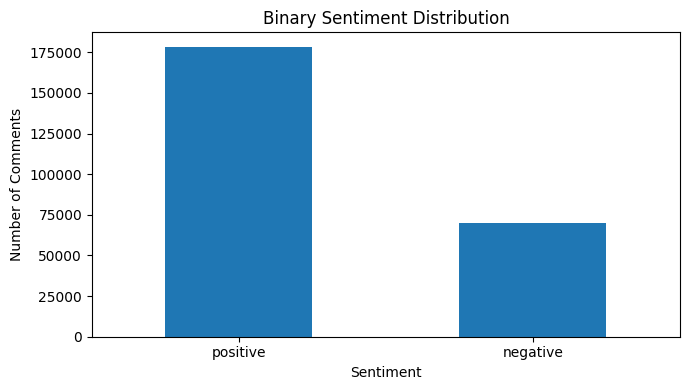

Saved binary dataset: /content/cse477_outputs/cleaned_binary_youtube_comments.csv

####################################################################################################
Running Experiment: Binary_Positive_vs_Negative
####################################################################################################

Experiment dataset shape: (248250, 6)
Label distribution:
sentiment
positive    178368
negative     69882
Name: count, dtype: int64

Creating TF-IDF features without data leakage...
TF-IDF completed.
TF-IDF time: 14.38 seconds
X_train shape: (173775, 5000)
X_test shape: (74475, 5000)

KNN will be run on a sample to avoid excessive runtime.

Running KNN sample models...


Binary_Positive_vs_Negative KNN Progress:   0%|          | 0/4 [00:00<?, ?it/s]


[Binary_Positive_vs_Negative_KNN_SAMPLE] Starting Model 1/4: KNN Sample Cosine k=3
Estimated remaining time: Calculating after first model finishes...

Training started...
Training completed for KNN Sample Cosine k=3.
Training time: 0.05 seconds

Prediction started...
Prediction completed for KNN Sample Cosine k=3.
Prediction time: 31.34 seconds

Calculating evaluation metrics...
Metric calculation completed.
Metric calculation time: 0.49 seconds

------------------------------------------------------------------------------------------
Result for KNN Sample Cosine k=3
------------------------------------------------------------------------------------------
Accuracy: 0.7964
Weighted Precision: 0.7895
Weighted Recall: 0.7964
Weighted F1-score: 0.7916
Macro F1-score: 0.7365

Classification Report:
              precision    recall  f1-score   support

    negative       0.66      0.57      0.61      5054
    positive       0.84      0.88      0.86     12946

    accuracy               

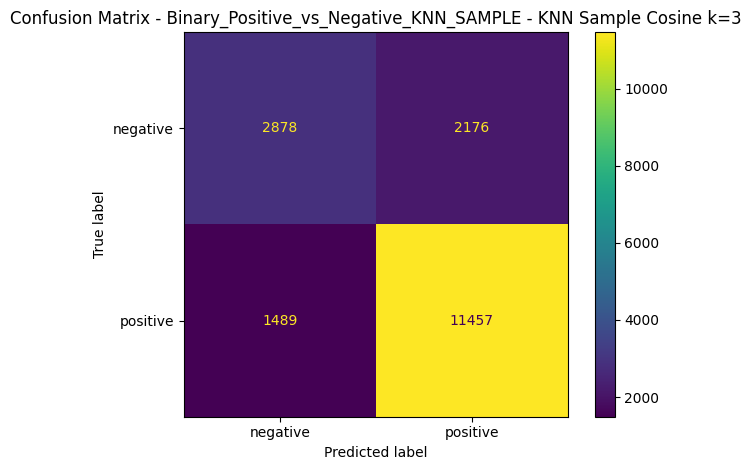

Saved confusion matrix: /content/cse477_outputs/confusion_matrix_Binary_Positive_vs_Negative_KNN_SAMPLE_KNN_Sample_Cosine_k_3.png
Misclassified examples saved: /content/cse477_outputs/misclassified_examples_Binary_Positive_vs_Negative_KNN_SAMPLE_KNN_Sample_Cosine_k_3.csv
Number of misclassified examples: 3665


,comment_text,clean_text,vader_score,original_label,true_label,predicted_label
39976,"the sound design of the shooting, explosions a...",the sound design of the shooting explosions an...,0.5859,positive,positive,negative
37753,Could you believe I could be different?\nI'll ...,could you believe i could be different ni ll b...,0.9906,positive,positive,negative
25560,But flipz don't talk like he's got no mouth??????,but flipz don t talk like he s got no mouth,-0.7525,negative,negative,positive
56434,You're cool. We should hang out sometimes. We ...,you are cool we should hang out sometimes we c...,-0.3400,negative,negative,positive
51426,I usually skip past brand deal ads but because...,i usually skip past brand deal ads but because...,0.7700,positive,positive,negative
25442,If only he'd be as keen to get his hands on th...,if only he d be as keen to get his hands on th...,0.3612,positive,positive,negative
12054,Looks like fake. However anything can be spect...,looks like fake however anything can be specte...,-0.1531,negative,negative,positive
24993,Look at highest rate of diabetic and obesity d...,look at highest rate of diabetic and obesity d...,-0.0572,negative,negative,positive
42925,"Well honey, do you...",well honey do you,0.2732,positive,positive,negative
40539,A hair video from Jackie has been thr highligh...,a hair video from jackie has been thr highligh...,-0.1779,negative,negative,positive



------------------------------------------------------------------------------------------
Completed Model 1/4: KNN Sample Cosine k=3
Actual total time: 32.78 seconds
------------------------------------------------------------------------------------------

[Binary_Positive_vs_Negative_KNN_SAMPLE] Starting Model 2/4: KNN Sample Cosine k=5
Overall elapsed time so far: 32.80 seconds
Estimated remaining time: 1.64 minutes

Training started...
Training completed for KNN Sample Cosine k=5.
Training time: 0.05 seconds

Prediction started...
Prediction completed for KNN Sample Cosine k=5.
Prediction time: 18.18 seconds

Calculating evaluation metrics...
Metric calculation completed.
Metric calculation time: 0.51 seconds

------------------------------------------------------------------------------------------
Result for KNN Sample Cosine k=5
------------------------------------------------------------------------------------------
Accuracy: 0.8119
Weighted Precision: 0.8042
Weighted Recall

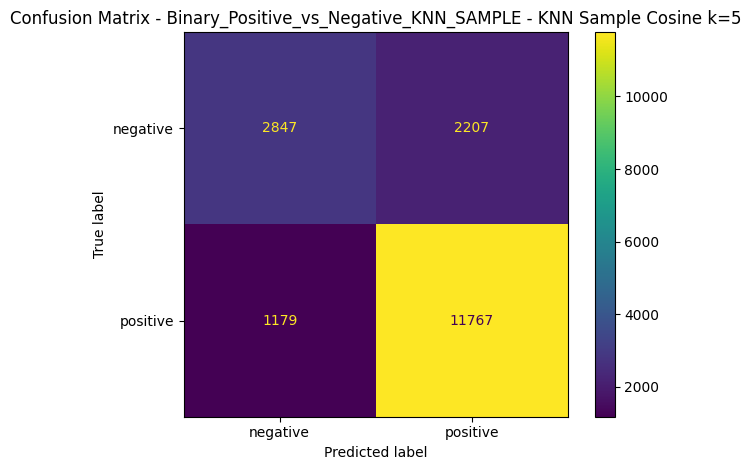

Saved confusion matrix: /content/cse477_outputs/confusion_matrix_Binary_Positive_vs_Negative_KNN_SAMPLE_KNN_Sample_Cosine_k_5.png
Misclassified examples saved: /content/cse477_outputs/misclassified_examples_Binary_Positive_vs_Negative_KNN_SAMPLE_KNN_Sample_Cosine_k_5.csv
Number of misclassified examples: 3386


,comment_text,clean_text,vader_score,original_label,true_label,predicted_label
25560,But flipz don't talk like he's got no mouth??????,but flipz don t talk like he s got no mouth,-0.7525,negative,negative,positive
56434,You're cool. We should hang out sometimes. We ...,you are cool we should hang out sometimes we c...,-0.3400,negative,negative,positive
51426,I usually skip past brand deal ads but because...,i usually skip past brand deal ads but because...,0.7700,positive,positive,negative
12054,Looks like fake. However anything can be spect...,looks like fake however anything can be specte...,-0.1531,negative,negative,positive
24993,Look at highest rate of diabetic and obesity d...,look at highest rate of diabetic and obesity d...,-0.0572,negative,negative,positive
42925,"Well honey, do you...",well honey do you,0.2732,positive,positive,negative
40539,A hair video from Jackie has been thr highligh...,a hair video from jackie has been thr highligh...,-0.1779,negative,negative,positive
48796,I remember I was literally one of the first pe...,i remember i was literally one of the first pe...,-0.3252,negative,negative,positive
11659,its true women walk around with there boobs ou...,its true women walk around with there boobs ou...,-0.2023,negative,negative,positive
8402,Years ago she would have been absolutely mobbe...,years ago she would have been absolutely mobbe...,-0.2411,negative,negative,positive



------------------------------------------------------------------------------------------
Completed Model 2/4: KNN Sample Cosine k=5
Actual total time: 19.57 seconds
------------------------------------------------------------------------------------------

[Binary_Positive_vs_Negative_KNN_SAMPLE] Starting Model 3/4: KNN Sample Cosine k=7
Overall elapsed time so far: 52.37 seconds
Estimated remaining time: 52.37 seconds

Training started...
Training completed for KNN Sample Cosine k=7.
Training time: 0.05 seconds

Prediction started...
Prediction completed for KNN Sample Cosine k=7.
Prediction time: 17.95 seconds

Calculating evaluation metrics...
Metric calculation completed.
Metric calculation time: 0.96 seconds

------------------------------------------------------------------------------------------
Result for KNN Sample Cosine k=7
------------------------------------------------------------------------------------------
Accuracy: 0.817
Weighted Precision: 0.8095
Weighted Recall

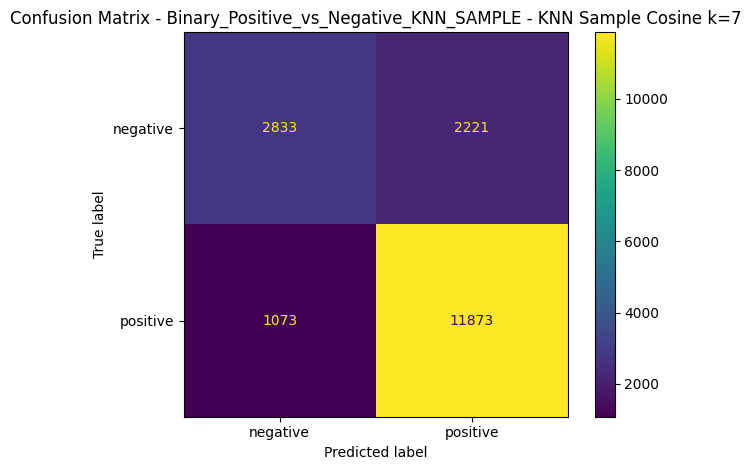

Saved confusion matrix: /content/cse477_outputs/confusion_matrix_Binary_Positive_vs_Negative_KNN_SAMPLE_KNN_Sample_Cosine_k_7.png
Misclassified examples saved: /content/cse477_outputs/misclassified_examples_Binary_Positive_vs_Negative_KNN_SAMPLE_KNN_Sample_Cosine_k_7.csv
Number of misclassified examples: 3294


,comment_text,clean_text,vader_score,original_label,true_label,predicted_label
25560,But flipz don't talk like he's got no mouth??????,but flipz don t talk like he s got no mouth,-0.7525,negative,negative,positive
56434,You're cool. We should hang out sometimes. We ...,you are cool we should hang out sometimes we c...,-0.3400,negative,negative,positive
12054,Looks like fake. However anything can be spect...,looks like fake however anything can be specte...,-0.1531,negative,negative,positive
24993,Look at highest rate of diabetic and obesity d...,look at highest rate of diabetic and obesity d...,-0.0572,negative,negative,positive
42925,"Well honey, do you...",well honey do you,0.2732,positive,positive,negative
40539,A hair video from Jackie has been thr highligh...,a hair video from jackie has been thr highligh...,-0.1779,negative,negative,positive
48796,I remember I was literally one of the first pe...,i remember i was literally one of the first pe...,-0.3252,negative,negative,positive
11659,its true women walk around with there boobs ou...,its true women walk around with there boobs ou...,-0.2023,negative,negative,positive
8402,Years ago she would have been absolutely mobbe...,years ago she would have been absolutely mobbe...,-0.2411,negative,negative,positive
20001,I have never watched game of thrones and now I...,i have never watched game of thrones and now i...,-0.8207,negative,negative,positive



------------------------------------------------------------------------------------------
Completed Model 3/4: KNN Sample Cosine k=7
Actual total time: 20.34 seconds
------------------------------------------------------------------------------------------

[Binary_Positive_vs_Negative_KNN_SAMPLE] Starting Model 4/4: KNN Sample Cosine k=9
Overall elapsed time so far: 1.21 minutes
Estimated remaining time: 24.24 seconds

Training started...
Training completed for KNN Sample Cosine k=9.
Training time: 0.09 seconds

Prediction started...
Prediction completed for KNN Sample Cosine k=9.
Prediction time: 18.06 seconds

Calculating evaluation metrics...
Metric calculation completed.
Metric calculation time: 0.49 seconds

------------------------------------------------------------------------------------------
Result for KNN Sample Cosine k=9
------------------------------------------------------------------------------------------
Accuracy: 0.8227
Weighted Precision: 0.8159
Weighted Recall

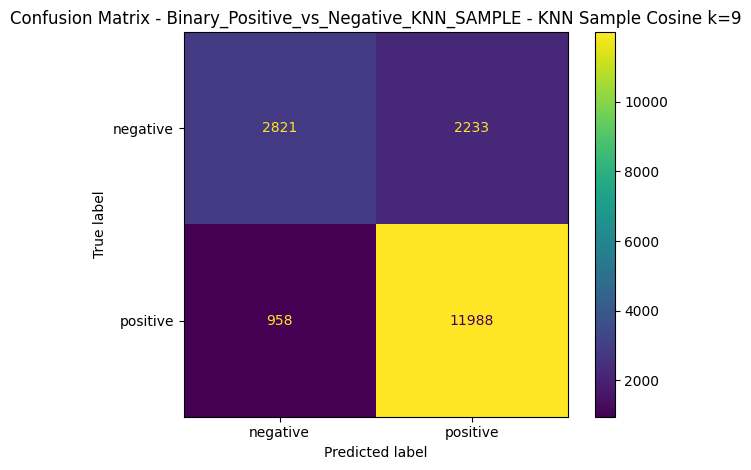

Saved confusion matrix: /content/cse477_outputs/confusion_matrix_Binary_Positive_vs_Negative_KNN_SAMPLE_KNN_Sample_Cosine_k_9.png
Misclassified examples saved: /content/cse477_outputs/misclassified_examples_Binary_Positive_vs_Negative_KNN_SAMPLE_KNN_Sample_Cosine_k_9.csv
Number of misclassified examples: 3191


,comment_text,clean_text,vader_score,original_label,true_label,predicted_label
25560,But flipz don't talk like he's got no mouth??????,but flipz don t talk like he s got no mouth,-0.7525,negative,negative,positive
56434,You're cool. We should hang out sometimes. We ...,you are cool we should hang out sometimes we c...,-0.3400,negative,negative,positive
51426,I usually skip past brand deal ads but because...,i usually skip past brand deal ads but because...,0.7700,positive,positive,negative
12054,Looks like fake. However anything can be spect...,looks like fake however anything can be specte...,-0.1531,negative,negative,positive
24993,Look at highest rate of diabetic and obesity d...,look at highest rate of diabetic and obesity d...,-0.0572,negative,negative,positive
39960,I COULDN'T STOP LAUGHING ONCE YOU PUT THE TEET...,i couldn t stop laughing once you put the teet...,-0.1877,negative,negative,positive
40539,A hair video from Jackie has been thr highligh...,a hair video from jackie has been thr highligh...,-0.1779,negative,negative,positive
48796,I remember I was literally one of the first pe...,i remember i was literally one of the first pe...,-0.3252,negative,negative,positive
11659,its true women walk around with there boobs ou...,its true women walk around with there boobs ou...,-0.2023,negative,negative,positive
8402,Years ago she would have been absolutely mobbe...,years ago she would have been absolutely mobbe...,-0.2411,negative,negative,positive



------------------------------------------------------------------------------------------
Completed Model 4/4: KNN Sample Cosine k=9
Actual total time: 19.47 seconds
------------------------------------------------------------------------------------------

KNN sample models completed.

Models to run:
1. Multinomial Naive Bayes
2. Logistic Regression
3. Linear SVM


Binary_Positive_vs_Negative Model Progress:   0%|          | 0/3 [00:00<?, ?it/s]


[Binary_Positive_vs_Negative] Starting Model 1/3: Multinomial Naive Bayes
Estimated remaining time: Calculating after first model finishes...

Training started...
Training completed for Multinomial Naive Bayes.
Training time: 0.50 seconds

Prediction started...
Prediction completed for Multinomial Naive Bayes.
Prediction time: 0.01 seconds

Calculating evaluation metrics...
Metric calculation completed.
Metric calculation time: 1.89 seconds

------------------------------------------------------------------------------------------
Result for Multinomial Naive Bayes
------------------------------------------------------------------------------------------
Accuracy: 0.8632
Weighted Precision: 0.8602
Weighted Recall: 0.8632
Weighted F1-score: 0.858
Macro F1-score: 0.8188

Classification Report:
              precision    recall  f1-score   support

    negative       0.82      0.65      0.73     20965
    positive       0.87      0.95      0.91     53510

    accuracy                    

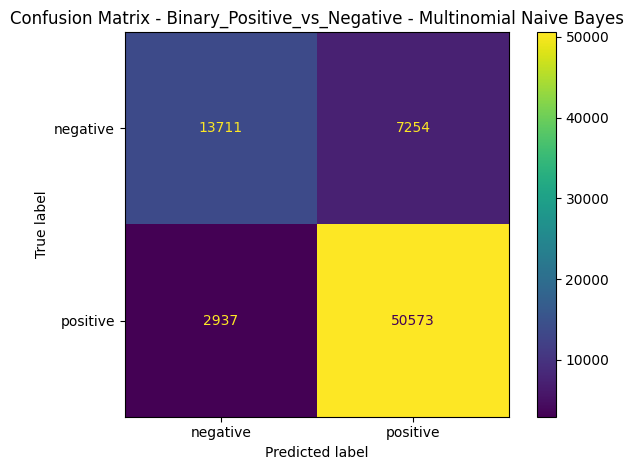

Saved confusion matrix: /content/cse477_outputs/confusion_matrix_Binary_Positive_vs_Negative_Multinomial_Naive_Bayes.png
Misclassified examples saved: /content/cse477_outputs/misclassified_examples_Binary_Positive_vs_Negative_Multinomial_Naive_Bayes.csv
Number of misclassified examples: 10191


,comment_text,clean_text,vader_score,original_label,true_label,predicted_label
3,The photos are fire 😍🔥,the photos are fire smiling face with heart ey...,-0.2023,negative,negative,positive
5,OMG SO CUTTTEEEE JUST WANT TO HUGE SO BAD,omg so cuttteeee just want to huge so bad,-0.3874,negative,negative,positive
13,I had a beautiful siamese named Oscar who died...,i had a beautiful siamese named oscar who died...,0.5216,positive,positive,negative
15,Ouuuuuuuuuuuuu you had to know it 🔥🔥🔥🔥🔥🔥🔥🐐🐐🐐🐐🐐🐐,ouuuuuuuuuuuuu you had to know it fire fire fi...,-0.9300,negative,negative,positive
21,Stop putting misleading titles please otherwis...,stop putting misleading titles please otherwis...,-0.3818,negative,negative,positive
29,What's her pedigree look like? Bloodlines? DNA...,what s her pedigree look like bloodlines dna t...,0.7862,positive,positive,negative
35,The first time I had that I tried to square up...,the first time i had that i tried to square up...,-0.3182,negative,negative,positive
41,And people complained about BvS is too dark...,and people complained about bvs is too dark,-0.4019,negative,negative,positive
48,Learn to paint and change out that boring artw...,learn to paint and change out that boring artw...,-0.3182,negative,negative,positive
57,"Shannon has good points, however, Shannon made...",shannon has good points however shannon made h...,0.6720,positive,positive,negative



------------------------------------------------------------------------------------------
Completed Model 1/3: Multinomial Naive Bayes
Actual total time: 3.99 seconds
------------------------------------------------------------------------------------------

[Binary_Positive_vs_Negative] Starting Model 2/3: Logistic Regression
Overall elapsed time so far: 4.01 seconds
Estimated remaining time: 8.02 seconds

Training started...
Training completed for Logistic Regression.
Training time: 3.45 seconds

Prediction started...
Prediction completed for Logistic Regression.
Prediction time: 0.00 seconds

Calculating evaluation metrics...
Metric calculation completed.
Metric calculation time: 3.84 seconds

------------------------------------------------------------------------------------------
Result for Logistic Regression
------------------------------------------------------------------------------------------
Accuracy: 0.8954
Weighted Precision: 0.9056
Weighted Recall: 0.8954
Weighted F1

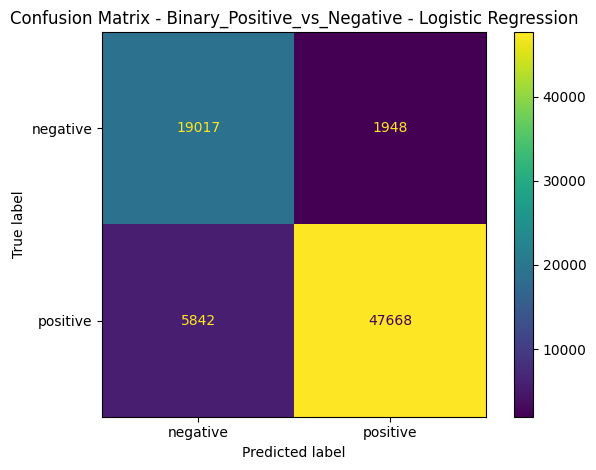

Saved confusion matrix: /content/cse477_outputs/confusion_matrix_Binary_Positive_vs_Negative_Logistic_Regression.png
Misclassified examples saved: /content/cse477_outputs/misclassified_examples_Binary_Positive_vs_Negative_Logistic_Regression.csv
Number of misclassified examples: 7790


,comment_text,clean_text,vader_score,original_label,true_label,predicted_label
3,The photos are fire 😍🔥,the photos are fire smiling face with heart ey...,-0.2023,negative,negative,positive
13,I had a beautiful siamese named Oscar who died...,i had a beautiful siamese named oscar who died...,0.5216,positive,positive,negative
29,What's her pedigree look like? Bloodlines? DNA...,what s her pedigree look like bloodlines dna t...,0.7862,positive,positive,negative
36,When did you go to the Isle of Wight? I live t...,when did you go to the isle of wight i live th...,0.4019,positive,positive,negative
57,"Shannon has good points, however, Shannon made...",shannon has good points however shannon made h...,0.6720,positive,positive,negative
72,Guys where's the 4ou tour vid...??😭❤❤,guys where s the ou tour vid loudly crying fac...,0.7691,positive,positive,negative
75,THE BEGGININF IS THE TRUEST THING EVERR,the beggininf is the truest thing everr,0.4404,positive,positive,negative
89,Who's not gonna see him forever? Coz you live ...,who s not gonna see him forever coz you live i...,0.2359,positive,positive,negative
106,sweat is not what stinks!!!!! its the bacteria...,sweat is not what stinks its the bacteria feed...,0.4419,positive,positive,negative
118,"When you rap about rape, drugs, sex and killin...",when you rap about rape drugs sex and killing ...,0.4310,positive,positive,negative



------------------------------------------------------------------------------------------
Completed Model 2/3: Logistic Regression
Actual total time: 8.88 seconds
------------------------------------------------------------------------------------------

[Binary_Positive_vs_Negative] Starting Model 3/3: Linear SVM
Overall elapsed time so far: 12.89 seconds
Estimated remaining time: 6.45 seconds

Training started...
Training completed for Linear SVM.
Training time: 2.79 seconds

Prediction started...
Prediction completed for Linear SVM.
Prediction time: 0.00 seconds

Calculating evaluation metrics...
Metric calculation completed.
Metric calculation time: 2.20 seconds

------------------------------------------------------------------------------------------
Result for Linear SVM
------------------------------------------------------------------------------------------
Accuracy: 0.8962
Weighted Precision: 0.9054
Weighted Recall: 0.8962
Weighted F1-score: 0.8985
Macro F1-score: 0.8777



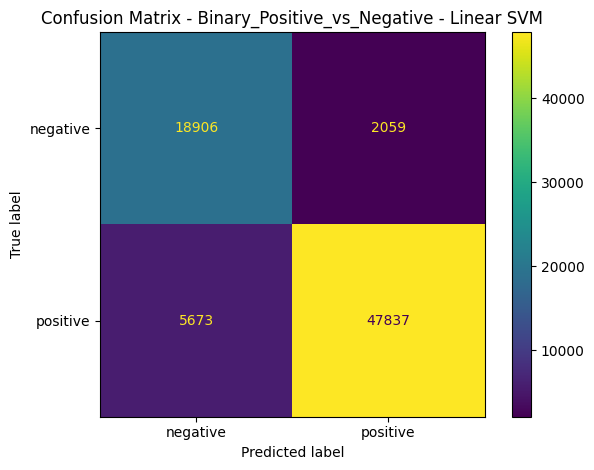

Saved confusion matrix: /content/cse477_outputs/confusion_matrix_Binary_Positive_vs_Negative_Linear_SVM.png
Misclassified examples saved: /content/cse477_outputs/misclassified_examples_Binary_Positive_vs_Negative_Linear_SVM.csv
Number of misclassified examples: 7732


,comment_text,clean_text,vader_score,original_label,true_label,predicted_label
0,I heard your voice and subscribed immediatly <3,i heard your voice and subscribed immediatly,0.4404,positive,positive,negative
3,The photos are fire 😍🔥,the photos are fire smiling face with heart ey...,-0.2023,negative,negative,positive
13,I had a beautiful siamese named Oscar who died...,i had a beautiful siamese named oscar who died...,0.5216,positive,positive,negative
29,What's her pedigree look like? Bloodlines? DNA...,what s her pedigree look like bloodlines dna t...,0.7862,positive,positive,negative
36,When did you go to the Isle of Wight? I live t...,when did you go to the isle of wight i live th...,0.4019,positive,positive,negative
57,"Shannon has good points, however, Shannon made...",shannon has good points however shannon made h...,0.6720,positive,positive,negative
72,Guys where's the 4ou tour vid...??😭❤❤,guys where s the ou tour vid loudly crying fac...,0.7691,positive,positive,negative
75,THE BEGGININF IS THE TRUEST THING EVERR,the beggininf is the truest thing everr,0.4404,positive,positive,negative
89,Who's not gonna see him forever? Coz you live ...,who s not gonna see him forever coz you live i...,0.2359,positive,positive,negative
106,sweat is not what stinks!!!!! its the bacteria...,sweat is not what stinks its the bacteria feed...,0.4419,positive,positive,negative



------------------------------------------------------------------------------------------
Completed Model 3/3: Linear SVM
Actual total time: 6.61 seconds
------------------------------------------------------------------------------------------

Final Result Table:


,Experiment,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,Precision_macro,Recall_macro,F1_macro,Training_Time,Prediction_Time,Metric_Time,Total_Time,Note,Training_Time_Readable,Prediction_Time_Readable,Metric_Time_Readable,Total_Time_Readable
0,Binary_Positive_vs_Negative,Linear SVM,0.8962,0.9054,0.8962,0.8985,0.8640,0.8979,0.8777,2.7891,0.0033,2.2033,4.9957,Full experiment dataset,2.79 seconds,0.00 seconds,2.20 seconds,5.00 seconds
1,Binary_Positive_vs_Negative,Logistic Regression,0.8954,0.9056,0.8954,0.8979,0.8629,0.8990,0.8772,3.4487,0.0044,3.8361,7.2892,Full experiment dataset,3.45 seconds,0.00 seconds,3.84 seconds,7.29 seconds
2,Binary_Positive_vs_Negative,Multinomial Naive Bayes,0.8632,0.8602,0.8632,0.8580,0.8491,0.7996,0.8188,0.4961,0.0076,1.8893,2.3929,Full experiment dataset,0.50 seconds,0.01 seconds,1.89 seconds,2.39 seconds
3,Binary_Positive_vs_Negative_KNN_SAMPLE,KNN Sample Cosine k=9,0.8227,0.8159,0.8227,0.8141,0.7947,0.7421,0.7606,0.0915,18.0601,0.4851,18.6367,KNN trained on sample size 60000,0.09 seconds,18.06 seconds,0.49 seconds,18.64 seconds
4,Binary_Positive_vs_Negative_KNN_SAMPLE,KNN Sample Cosine k=7,0.8170,0.8095,0.8170,0.8092,0.7839,0.7388,0.7553,0.0546,17.9471,0.9623,18.9641,KNN trained on sample size 60000,0.05 seconds,17.95 seconds,0.96 seconds,18.96 seconds
5,Binary_Positive_vs_Negative_KNN_SAMPLE,KNN Sample Cosine k=5,0.8119,0.8042,0.8119,0.8048,0.7746,0.7361,0.7507,0.0481,18.1760,0.5136,18.7377,KNN trained on sample size 60000,0.05 seconds,18.18 seconds,0.51 seconds,18.74 seconds
6,Binary_Positive_vs_Negative_KNN_SAMPLE,KNN Sample Cosine k=3,0.7964,0.7895,0.7964,0.7916,0.7497,0.7272,0.7365,0.0526,31.3433,0.4890,31.8849,KNN trained on sample size 60000,0.05 seconds,31.34 seconds,0.49 seconds,31.88 seconds


Saved result table: /content/cse477_outputs/results_Binary_Positive_vs_Negative.csv


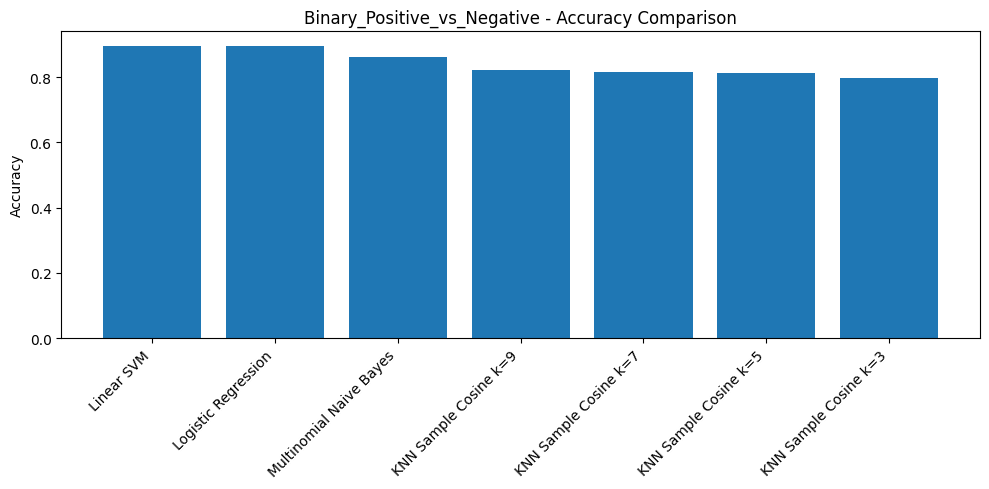

Saved figure: /content/cse477_outputs/Binary_Positive_vs_Negative_Accuracy_comparison.png


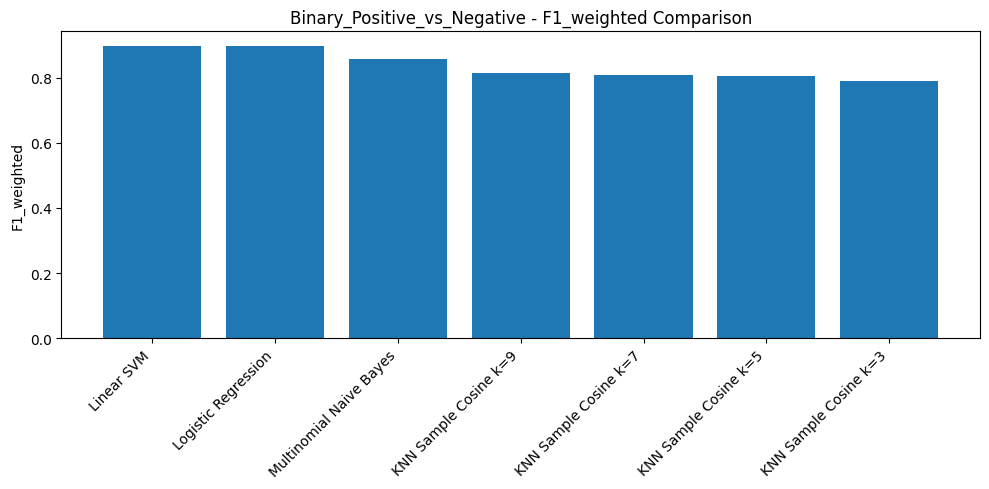

Saved figure: /content/cse477_outputs/Binary_Positive_vs_Negative_F1_weighted_comparison.png


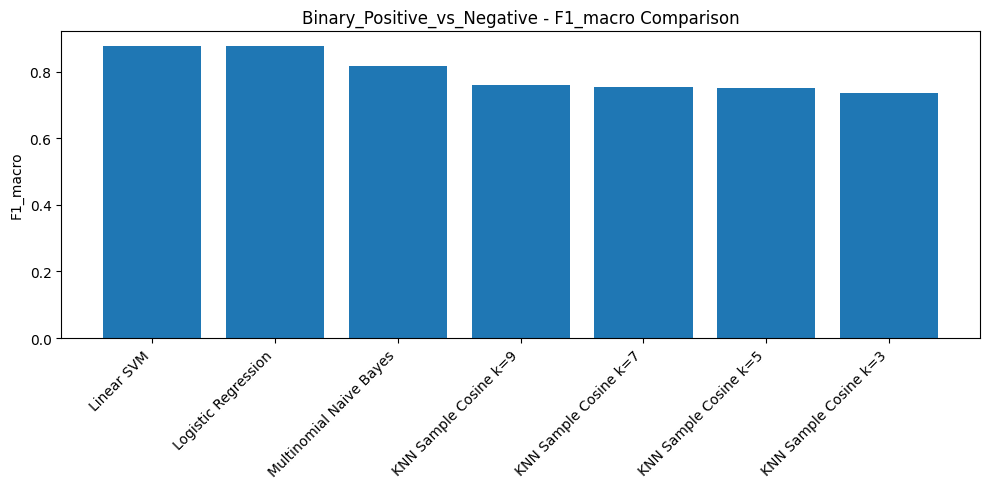

Saved figure: /content/cse477_outputs/Binary_Positive_vs_Negative_F1_macro_comparison.png


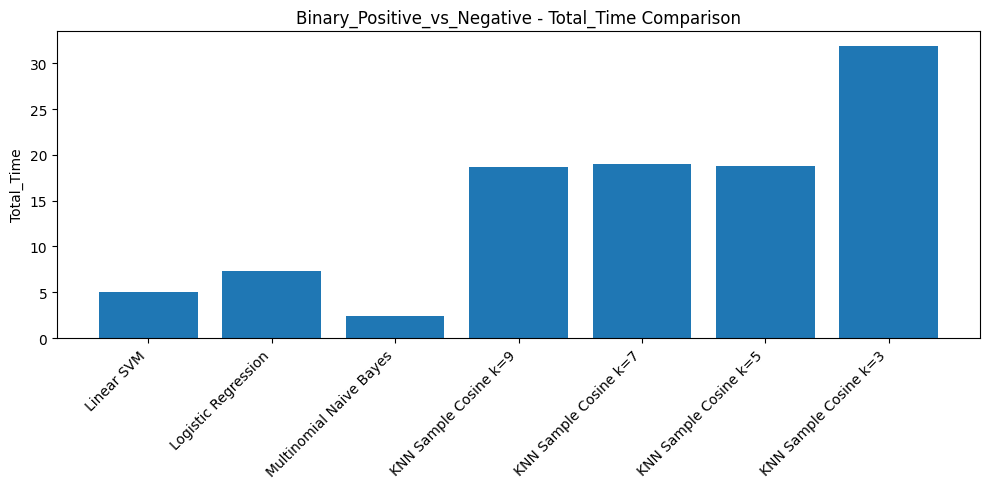

Saved figure: /content/cse477_outputs/Binary_Positive_vs_Negative_Total_Time_comparison.png


In [ ]:
# ============================================================
# 14. Binary Classification Experiment
# Positive vs Negative
# ============================================================

df_binary = df[df["sentiment"].isin(["positive", "negative"])].copy()
df_binary = df_binary.reset_index(drop=True)

print("Binary dataset shape:", df_binary.shape)
print("Binary sentiment distribution:")
print(df_binary["sentiment"].value_counts())

plt.figure(figsize=(7, 4))
df_binary["sentiment"].value_counts().plot(kind="bar")
plt.title("Binary Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Comments")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "/content/drive/MyDrive/CSE477/project/binary_sentiment_distribution.png"), dpi=300)
plt.show()

binary_output_path = os.path.join(OUTPUT_DIR, "/content/drive/MyDrive/CSE477/project/cleaned_binary_youtube_comments.csv")
df_binary.to_csv(binary_output_path, index=False)
print("Saved binary dataset:", binary_output_path)

binary_experiment = run_experiment(
    df_experiment=df_binary,
    experiment_name="Binary_Positive_vs_Negative",
    label_col="sentiment",
    include_knn=RUN_KNN,
    knn_sample_size=KNN_SAMPLE_SIZE
)

Multiclass dataset shape: (337850, 6)
Multiclass sentiment distribution:
sentiment
positive    178368
neutral      89600
negative     69882
Name: count, dtype: int64


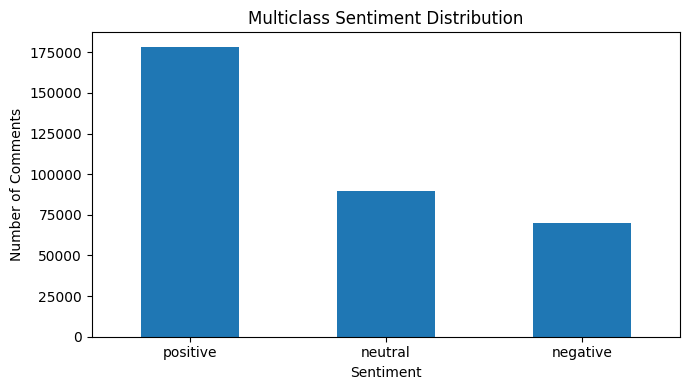

Saved multiclass dataset: /content/cse477_outputs/cleaned_multiclass_youtube_comments.csv

####################################################################################################
Running Experiment: Multiclass_Positive_Negative_Neutral
####################################################################################################

Experiment dataset shape: (337850, 6)
Label distribution:
sentiment
positive    178368
neutral      89600
negative     69882
Name: count, dtype: int64

Creating TF-IDF features without data leakage...
TF-IDF completed.
TF-IDF time: 16.26 seconds
X_train shape: (236495, 5000)
X_test shape: (101355, 5000)

Models to run:
1. Multinomial Naive Bayes
2. Logistic Regression
3. Linear SVM


Multiclass_Positive_Negative_Neutral Model Progress:   0%|          | 0/3 [00:00<?, ?it/s]


[Multiclass_Positive_Negative_Neutral] Starting Model 1/3: Multinomial Naive Bayes
Estimated remaining time: Calculating after first model finishes...

Training started...
Training completed for Multinomial Naive Bayes.
Training time: 0.60 seconds

Prediction started...
Prediction completed for Multinomial Naive Bayes.
Prediction time: 0.01 seconds

Calculating evaluation metrics...
Metric calculation completed.
Metric calculation time: 2.03 seconds

------------------------------------------------------------------------------------------
Result for Multinomial Naive Bayes
------------------------------------------------------------------------------------------
Accuracy: 0.7513
Weighted Precision: 0.7547
Weighted Recall: 0.7513
Weighted F1-score: 0.7427
Macro F1-score: 0.7154

Classification Report:
              precision    recall  f1-score   support

    negative       0.79      0.60      0.69     20965
     neutral       0.75      0.57      0.65     26880
    positive       0.74

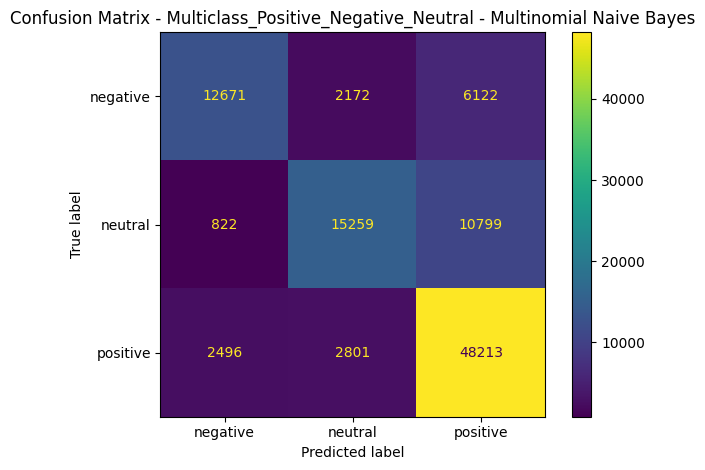

Saved confusion matrix: /content/cse477_outputs/confusion_matrix_Multiclass_Positive_Negative_Neutral_Multinomial_Naive_Bayes.png
Misclassified examples saved: /content/cse477_outputs/misclassified_examples_Multiclass_Positive_Negative_Neutral_Multinomial_Naive_Bayes.csv
Number of misclassified examples: 25212


,comment_text,clean_text,vader_score,original_label,true_label,predicted_label
4,Get all the Muslims out.,get all the muslims out,0.0000,neutral,neutral,negative
6,Casey Holmes tried that concealer and it burne...,casey holmes tried that concealer and it burne...,0.0000,neutral,neutral,positive
20,why is this video so aesthetically pleasing? s...,why is this video so aesthetically pleasing so...,0.0397,neutral,neutral,positive
23,relieve stomach second largely institution ful...,relieve stomach second largely institution ful...,0.3612,positive,positive,neutral
32,"No, but Morty has!! Just look at him go! Hahah...",no but morty has just look at him go hahahaha,0.0000,neutral,neutral,positive
41,Totally different one,totally different one,0.0000,neutral,neutral,positive
43,"Yayyyyy, the boss is back!",yayyyyy the boss is back,0.0000,neutral,neutral,positive
44,Well the name WAS Anthony Weiner,well the name was anthony weiner,0.2732,positive,positive,neutral
45,"If a metro don trust you, he gon shoot you.",if a metro don trust you he gon shoot you,0.2263,positive,positive,negative
53,12:52 who is that!,who is that,0.0000,neutral,neutral,positive



------------------------------------------------------------------------------------------
Completed Model 1/3: Multinomial Naive Bayes
Actual total time: 4.70 seconds
------------------------------------------------------------------------------------------

[Multiclass_Positive_Negative_Neutral] Starting Model 2/3: Logistic Regression
Overall elapsed time so far: 4.72 seconds
Estimated remaining time: 9.44 seconds

Training started...
Training completed for Logistic Regression.
Training time: 11.25 seconds

Prediction started...
Prediction completed for Logistic Regression.
Prediction time: 0.01 seconds

Calculating evaluation metrics...
Metric calculation completed.
Metric calculation time: 2.58 seconds

------------------------------------------------------------------------------------------
Result for Logistic Regression
------------------------------------------------------------------------------------------
Accuracy: 0.8726
Weighted Precision: 0.8804
Weighted Recall: 0.8726
W

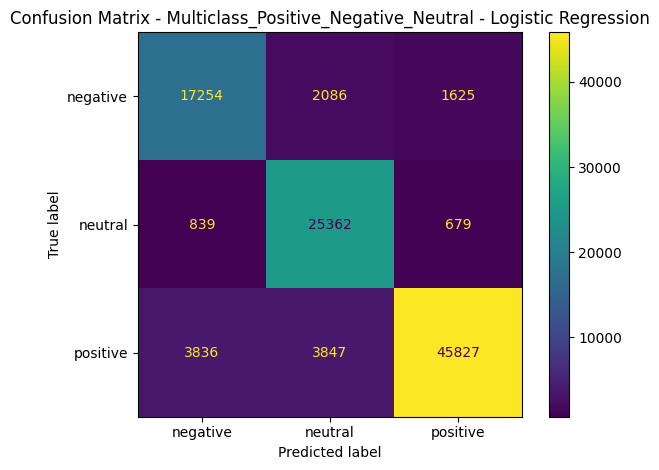

Saved confusion matrix: /content/cse477_outputs/confusion_matrix_Multiclass_Positive_Negative_Neutral_Logistic_Regression.png
Misclassified examples saved: /content/cse477_outputs/misclassified_examples_Multiclass_Positive_Negative_Neutral_Logistic_Regression.csv
Number of misclassified examples: 12912


,comment_text,clean_text,vader_score,original_label,true_label,predicted_label
20,why is this video so aesthetically pleasing? s...,why is this video so aesthetically pleasing so...,0.0397,neutral,neutral,positive
23,relieve stomach second largely institution ful...,relieve stomach second largely institution ful...,0.3612,positive,positive,neutral
32,"No, but Morty has!! Just look at him go! Hahah...",no but morty has just look at him go hahahaha,0.0000,neutral,neutral,negative
44,Well the name WAS Anthony Weiner,well the name was anthony weiner,0.2732,positive,positive,neutral
45,"If a metro don trust you, he gon shoot you.",if a metro don trust you he gon shoot you,0.2263,positive,positive,negative
50,“STEALING”. What a horrible statement! Shar...,stealing what a horrible statement sharing wit...,0.6229,positive,positive,negative
61,"Even if I played the video at 0.25 speed, I st...",even if i played the video at speed i still ca...,-0.1280,negative,negative,positive
65,Police gunned his brotha down now they loading...,police gunned his brotha down now they loading...,-0.8720,negative,negative,neutral
72,most under appreciated feature of Samsung gala...,most under appreciated feature of samsung gala...,0.7165,positive,positive,neutral
87,The ref done ok if you ask me. The Besiktas go...,the ref done ok if you ask me the besiktas goa...,0.1531,positive,positive,neutral



------------------------------------------------------------------------------------------
Completed Model 2/3: Logistic Regression
Actual total time: 15.92 seconds
------------------------------------------------------------------------------------------

[Multiclass_Positive_Negative_Neutral] Starting Model 3/3: Linear SVM
Overall elapsed time so far: 20.65 seconds
Estimated remaining time: 10.32 seconds

Training started...
Training completed for Linear SVM.
Training time: 10.66 seconds

Prediction started...
Prediction completed for Linear SVM.
Prediction time: 0.01 seconds

Calculating evaluation metrics...
Metric calculation completed.
Metric calculation time: 2.48 seconds

------------------------------------------------------------------------------------------
Result for Linear SVM
------------------------------------------------------------------------------------------
Accuracy: 0.8839
Weighted Precision: 0.8875
Weighted Recall: 0.8839
Weighted F1-score: 0.8842
Macro F1-sco

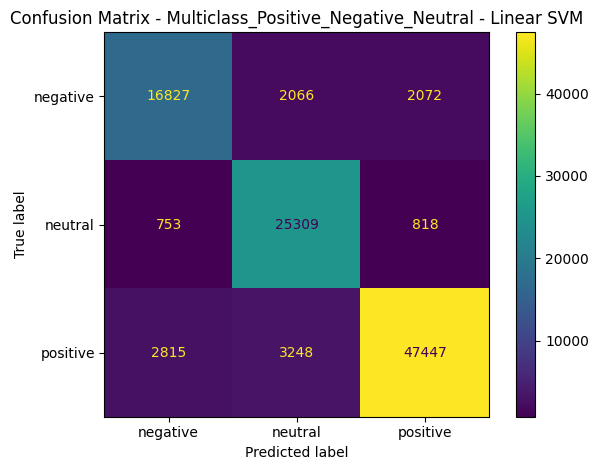

Saved confusion matrix: /content/cse477_outputs/confusion_matrix_Multiclass_Positive_Negative_Neutral_Linear_SVM.png
Misclassified examples saved: /content/cse477_outputs/misclassified_examples_Multiclass_Positive_Negative_Neutral_Linear_SVM.csv
Number of misclassified examples: 11772


,comment_text,clean_text,vader_score,original_label,true_label,predicted_label
20,why is this video so aesthetically pleasing? s...,why is this video so aesthetically pleasing so...,0.0397,neutral,neutral,positive
23,relieve stomach second largely institution ful...,relieve stomach second largely institution ful...,0.3612,positive,positive,neutral
32,"No, but Morty has!! Just look at him go! Hahah...",no but morty has just look at him go hahahaha,0.0000,neutral,neutral,negative
44,Well the name WAS Anthony Weiner,well the name was anthony weiner,0.2732,positive,positive,neutral
45,"If a metro don trust you, he gon shoot you.",if a metro don trust you he gon shoot you,0.2263,positive,positive,negative
50,“STEALING”. What a horrible statement! Shar...,stealing what a horrible statement sharing wit...,0.6229,positive,positive,negative
61,"Even if I played the video at 0.25 speed, I st...",even if i played the video at speed i still ca...,-0.1280,negative,negative,positive
65,Police gunned his brotha down now they loading...,police gunned his brotha down now they loading...,-0.8720,negative,negative,neutral
73,The best nasty animation I have ever watch!,the best nasty animation i have ever watch,0.2244,positive,positive,negative
87,The ref done ok if you ask me. The Besiktas go...,the ref done ok if you ask me the besiktas goa...,0.1531,positive,positive,neutral



------------------------------------------------------------------------------------------
Completed Model 3/3: Linear SVM
Actual total time: 15.45 seconds
------------------------------------------------------------------------------------------

Final Result Table:


,Experiment,Model,Accuracy,Precision_weighted,Recall_weighted,F1_weighted,Precision_macro,Recall_macro,F1_macro,Training_Time,Prediction_Time,Metric_Time,Total_Time,Note,Training_Time_Readable,Prediction_Time_Readable,Metric_Time_Readable,Total_Time_Readable
0,Multiclass_Positive_Negative_Neutral,Linear SVM,0.8839,0.8875,0.8839,0.8842,0.8647,0.8770,0.8692,10.6560,0.0097,2.4829,13.1485,Full experiment dataset,10.66 seconds,0.01 seconds,2.48 seconds,13.15 seconds
1,Multiclass_Positive_Negative_Neutral,Logistic Regression,0.8726,0.8804,0.8726,0.8737,0.8498,0.8743,0.8594,11.2491,0.0099,2.5776,13.8366,Full experiment dataset,11.25 seconds,0.01 seconds,2.58 seconds,13.84 seconds
2,Multiclass_Positive_Negative_Neutral,Multinomial Naive Bayes,0.7513,0.7547,0.7513,0.7427,0.7623,0.6910,0.7154,0.6046,0.0099,2.0307,2.6452,Full experiment dataset,0.60 seconds,0.01 seconds,2.03 seconds,2.65 seconds


Saved result table: /content/cse477_outputs/results_Multiclass_Positive_Negative_Neutral.csv


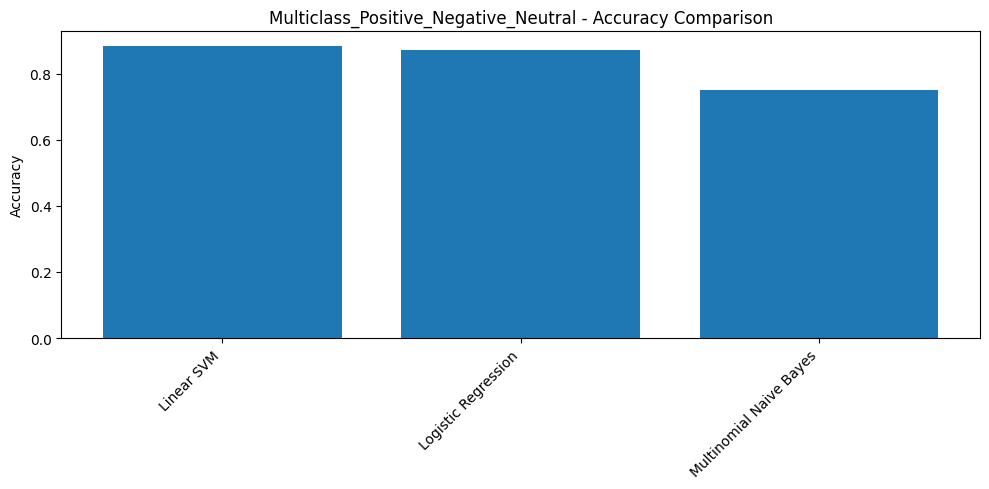

Saved figure: /content/cse477_outputs/Multiclass_Positive_Negative_Neutral_Accuracy_comparison.png


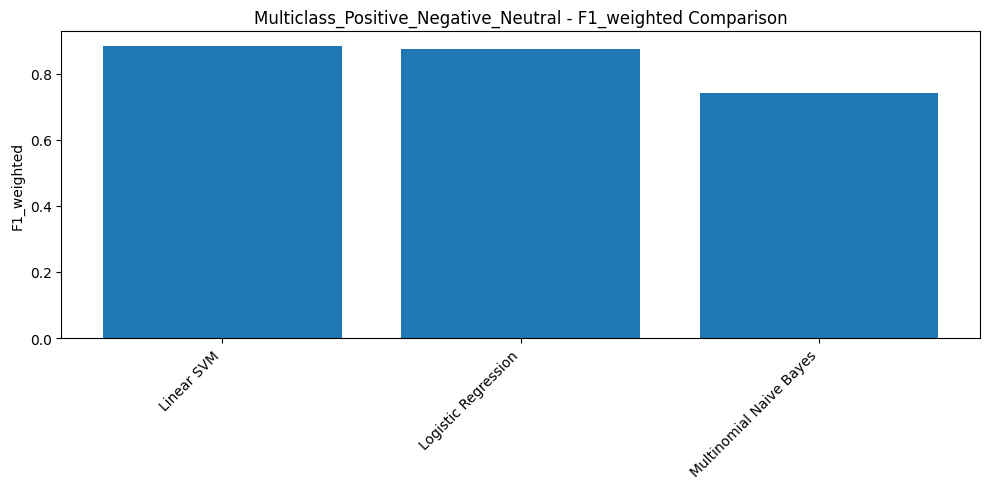

Saved figure: /content/cse477_outputs/Multiclass_Positive_Negative_Neutral_F1_weighted_comparison.png


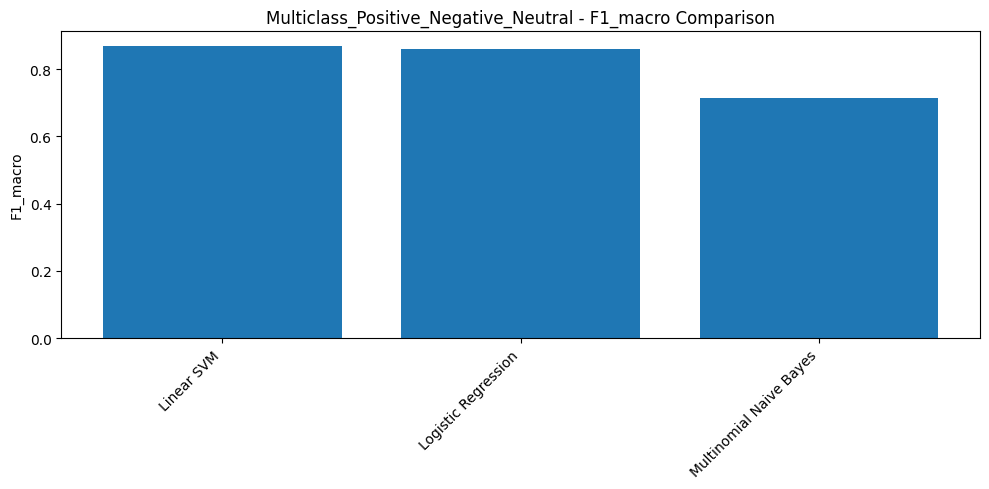

Saved figure: /content/cse477_outputs/Multiclass_Positive_Negative_Neutral_F1_macro_comparison.png


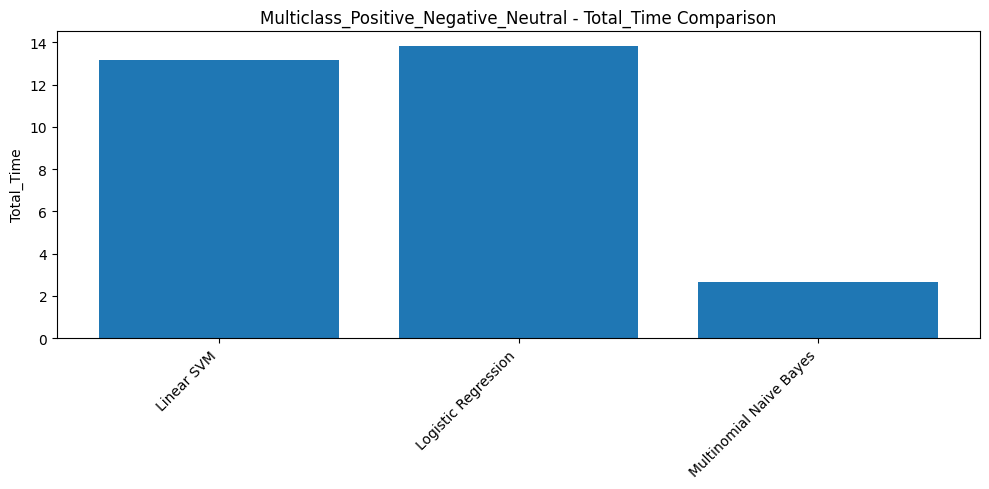

Saved figure: /content/cse477_outputs/Multiclass_Positive_Negative_Neutral_Total_Time_comparison.png


In [ ]:
# ============================================================
# 15. Multiclass Classification Experiment
# Positive vs Negative vs Neutral
# ============================================================

if RUN_MULTICLASS_EXPERIMENT:
    df_multiclass = df[df["sentiment"].isin(["positive", "negative", "neutral"])].copy()
    df_multiclass = df_multiclass.reset_index(drop=True)

    print("Multiclass dataset shape:", df_multiclass.shape)
    print("Multiclass sentiment distribution:")
    print(df_multiclass["sentiment"].value_counts())

    plt.figure(figsize=(7, 4))
    df_multiclass["sentiment"].value_counts().plot(kind="bar")
    plt.title("Multiclass Sentiment Distribution")
    plt.xlabel("Sentiment")
    plt.ylabel("Number of Comments")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, "multiclass_sentiment_distribution.png"), dpi=300)
    plt.show()

    multiclass_output_path = os.path.join(OUTPUT_DIR, "cleaned_multiclass_youtube_comments.csv")
    df_multiclass.to_csv(multiclass_output_path, index=False)
    print("Saved multiclass dataset:", multiclass_output_path)

    # For multiclass, KNN is usually skipped because it is slow.
    multiclass_experiment = run_experiment(
        df_experiment=df_multiclass,
        experiment_name="Multiclass_Positive_Negative_Neutral",
        label_col="sentiment",
        include_knn=False,
        knn_sample_size=KNN_SAMPLE_SIZE
    )
else:
    multiclass_experiment = None
    print("Multiclass experiment skipped.")

In [ ]:
# ============================================================
# 16. Cross-Validation for Strong Fast Models
# ============================================================

if RUN_CROSS_VALIDATION:
    print("\nRunning cross-validation on binary dataset...")

    if CV_SAMPLE_SIZE is not None and df_binary.shape[0] > CV_SAMPLE_SIZE:
        cv_df = df_binary.sample(
            n=CV_SAMPLE_SIZE,
            random_state=RANDOM_STATE
        ).reset_index(drop=True)
        print("Using CV sample size:", CV_SAMPLE_SIZE)
    else:
        cv_df = df_binary.copy()
        print("Using full binary dataset for CV.")

    X_cv_text = cv_df["clean_text"]
    y_cv = cv_df["sentiment"]

    from sklearn.pipeline import Pipeline

    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=RANDOM_STATE
    )

    cv_models = {
        "Logistic Regression": LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE,
            class_weight="balanced",
            n_jobs=-1
        ),
        "Linear SVM": LinearSVC(
            random_state=RANDOM_STATE,
            class_weight="balanced"
        )
    }

    cv_rows = []

    for model_name, model in cv_models.items():
        print("\n" + "=" * 70)
        print("Cross-validating:", model_name)
        print("=" * 70)

        pipeline = Pipeline([
            ("tfidf", TfidfVectorizer(
                max_features=MAX_FEATURES,
                stop_words=list(custom_stop_words),
                ngram_range=(1, 2),
                min_df=2,
                max_df=0.90
            )),
            ("model", model)
        ])

        start = time.time()

        weighted_f1_scores = cross_val_score(
            pipeline,
            X_cv_text,
            y_cv,
            cv=cv,
            scoring="f1_weighted",
            n_jobs=-1
        )

        macro_f1_scores = cross_val_score(
            pipeline,
            X_cv_text,
            y_cv,
            cv=cv,
            scoring="f1_macro",
            n_jobs=-1
        )

        end = time.time()

        print("Weighted F1 scores:", weighted_f1_scores)
        print("Mean weighted F1:", weighted_f1_scores.mean())
        print("Std weighted F1:", weighted_f1_scores.std())

        print("\nMacro F1 scores:", macro_f1_scores)
        print("Mean macro F1:", macro_f1_scores.mean())
        print("Std macro F1:", macro_f1_scores.std())

        print("\nCV time:", format_time(end - start))

        cv_rows.append({
            "Model": model_name,
            "Weighted_F1_Scores": weighted_f1_scores.tolist(),
            "Mean_Weighted_F1": weighted_f1_scores.mean(),
            "Std_Weighted_F1": weighted_f1_scores.std(),
            "Macro_F1_Scores": macro_f1_scores.tolist(),
            "Mean_Macro_F1": macro_f1_scores.mean(),
            "Std_Macro_F1": macro_f1_scores.std(),
            "CV_Time": end - start,
            "CV_Time_Readable": format_time(end - start),
            "CV_Sample_Size": cv_df.shape[0],
            "CV_Note": "TF-IDF was fitted inside each fold using Pipeline to avoid cross-validation leakage."
        })

    cv_results_df = pd.DataFrame(cv_rows)

    cv_path = os.path.join(OUTPUT_DIR, "/content/drive/MyDrive/CSE477/project/cross_validation_results.csv")
    cv_results_df.to_csv(cv_path, index=False)

    print("\nCross-validation result table:")
    display(cv_results_df)

    print("Saved cross-validation results:", cv_path)

else:
    print("Cross-validation skipped.")


Running cross-validation on binary dataset...
Using CV sample size: 100000

Cross-validating: Logistic Regression
Weighted F1 scores: [0.89501842 0.89215498 0.89817377 0.89153267 0.88868885]
Mean weighted F1: 0.8931137377980329
Std weighted F1: 0.003232037064401283

Macro F1 scores: [0.8736743  0.87042293 0.87786221 0.86987593 0.86643631]
Mean macro F1: 0.8716543355372774
Std macro F1: 0.0038606967620479172

CV time: 57.05 seconds

Cross-validating: Linear SVM
Weighted F1 scores: [0.89504837 0.89225976 0.89863241 0.89046414 0.88685281]
Mean weighted F1: 0.8926514966392002
Std weighted F1: 0.00400197556442064

Macro F1 scores: [0.87328379 0.87007802 0.87787461 0.8680302  0.86385127]
Mean macro F1: 0.8706235773227764
Std macro F1: 0.004744294579950744

CV time: 1.04 minutes

Cross-validation result table:


,Model,Weighted_F1_Scores,Mean_Weighted_F1,Std_Weighted_F1,Macro_F1_Scores,Mean_Macro_F1,Std_Macro_F1,CV_Time,CV_Time_Readable,CV_Sample_Size,CV_Note
0,Logistic Regression,"[0.8950184171287492, 0.8921549798269603, 0.898...",0.893114,0.003232,"[0.8736742998789715, 0.8704229258500997, 0.877...",0.871654,0.003861,57.052462,57.05 seconds,100000,TF-IDF was fitted inside each fold using Pipel...
1,Linear SVM,"[0.8950483669448087, 0.8922597600037685, 0.898...",0.892651,0.004002,"[0.8732837872941654, 0.8700780159683441, 0.877...",0.870624,0.004744,62.610451,1.04 minutes,100000,TF-IDF was fitted inside each fold using Pipel...


Saved cross-validation results: /content/cse477_outputs/cross_validation_results.csv


In [ ]:
binary_results_df = binary_experiment["results_df"]

best_binary_row = binary_results_df.iloc[0]

if multiclass_experiment is not None:
    multiclass_results_df = multiclass_experiment["results_df"]
    best_multiclass_row = multiclass_results_df.iloc[0]
else:
    multiclass_results_df = None
    best_multiclass_row = None


summary_text = f"""
CSE477 Micro-Extension Project Summary
=====================================

Dataset
-------
Comment files used: {', '.join([os.path.basename(f) for f in selected_files])}
Final cleaned dataset size after duplicate, spam/noise, and minimum-word filtering: {df.shape[0]}

Methodological Improvements
---------------------------
This corrected version improves the earlier KNN-based approach in several ways:

1. Sentiment labels are generated using VADER on raw comment_text, not cleaned text.
   This preserves punctuation, emojis, capitalization, and informal sentiment markers.

2. Spam/noise filtering is applied before modeling.
   Obvious URL comments, self-promotion comments, and very low-information comments are removed.

3. TF-IDF is fitted only on training text after train-test split.
   This avoids data leakage from the test set.

4. Stronger baseline models are added:
   - Multinomial Naive Bayes
   - Logistic Regression
   - Linear SVM

5. KNN is retained only as a comparative baseline.
   KNN is slow on high-dimensional sparse TF-IDF text, so it is run using a controlled sample if the dataset is large.

6. Both binary and multiclass experiments are included.
   Binary experiment: positive vs negative
   Multiclass experiment: positive vs negative vs neutral

7. Evaluation includes:
   - Accuracy
   - Weighted precision
   - Weighted recall
   - Weighted F1-score
   - Macro precision
   - Macro recall
   - Macro F1-score
   - Confusion matrix
   - Misclassified examples

8. Cross-validation is added for fast strong models where enabled.

Important Validity Note
-----------------------
The sentiment labels in this project are VADER-generated pseudo-labels, not human-annotated ground truth labels.
Therefore, model performance should be interpreted as the model's ability to reproduce VADER sentiment decisions,
not as definitive human-validated sentiment classification accuracy.

Best Binary Model
-----------------
Best model: {best_binary_row['Model']}
Accuracy: {best_binary_row['Accuracy']}
Weighted F1-score: {best_binary_row['F1_weighted']}
Macro F1-score: {best_binary_row['F1_macro']}
Total runtime: {best_binary_row['Total_Time_Readable']}
"""

if best_multiclass_row is not None:
    summary_text += f"""

Best Multiclass Model
---------------------
Best model: {best_multiclass_row['Model']}
Accuracy: {best_multiclass_row['Accuracy']}
Weighted F1-score: {best_multiclass_row['F1_weighted']}
Macro F1-score: {best_multiclass_row['F1_macro']}
Total runtime: {best_multiclass_row['Total_Time_Readable']}
"""

summary_path = os.path.join(OUTPUT_DIR, "/content/drive/MyDrive/CSE477/project/final_project_summary.txt")

with open(summary_path, "w", encoding="utf-8") as f:
    f.write(summary_text)

print(summary_text)
print("Saved final summary:", summary_path)


CSE477 Micro-Extension Project Summary

Dataset
-------
Comment files used: GBcomments.csv
Final cleaned dataset size after duplicate, spam/noise, and minimum-word filtering: 337850

Methodological Improvements
---------------------------
This corrected version improves the earlier KNN-based approach in several ways:

1. Sentiment labels are generated using VADER on raw comment_text, not cleaned text.
   This preserves punctuation, emojis, capitalization, and informal sentiment markers.

2. Spam/noise filtering is applied before modeling.
   Obvious URL comments, self-promotion comments, and very low-information comments are removed.

3. TF-IDF is fitted only on training text after train-test split.
   This avoids data leakage from the test set.

4. Stronger baseline models are added:
   - Multinomial Naive Bayes
   - Logistic Regression
   - Linear SVM

5. KNN is retained only as a comparative baseline.
   KNN is slow on high-dimensional sparse TF-IDF text, so it is run using a contr

In [ ]:
# ============================================================
# 19. List All Saved Output Files
# ============================================================

import shutil

new_output_dir = "/content/drive/MyDrive/CSE477/project/outputs"
os.makedirs(new_output_dir, exist_ok=True)

print("\nMoving all generated output files from", OUTPUT_DIR, "to", new_output_dir)

saved_files = glob.glob(os.path.join(OUTPUT_DIR, "*"))

for file_path in saved_files:
    try:
        shutil.move(file_path, new_output_dir)
        print(f"Moved: {os.path.basename(file_path)}")
    except Exception as e:
        print(f"Error moving {os.path.basename(file_path)}: {e}")

print("\nAll outputs moved successfully.")

# Update OUTPUT_DIR for any future saves in this session
OUTPUT_DIR = new_output_dir
print("Updated OUTPUT_DIR to:", OUTPUT_DIR)

# List files in the new directory
print("\nFiles in the new output directory:", OUTPUT_DIR)
files_in_new_dir = sorted(glob.glob(os.path.join(OUTPUT_DIR, "*")))
for file_path in files_in_new_dir:
    print("-", file_path)

print("\nFull corrected Colab-ready pipeline completed successfully.")


Moving all generated output files from /content/cse477_outputs to /content/drive/MyDrive/CSE477/project/outputs
Moved: Binary_Positive_vs_Negative_Total_Time_comparison.png
Moved: confusion_matrix_Multiclass_Positive_Negative_Neutral_Logistic_Regression.png
Moved: misclassified_examples_Multiclass_Positive_Negative_Neutral_Linear_SVM.csv
Moved: confusion_matrix_Binary_Positive_vs_Negative_KNN_SAMPLE_KNN_Sample_Cosine_k_9.png
Moved: misclassified_examples_Binary_Positive_vs_Negative_KNN_SAMPLE_KNN_Sample_Cosine_k_5.csv
Moved: confusion_matrix_Binary_Positive_vs_Negative_Logistic_Regression.png
Moved: misclassified_examples_Multiclass_Positive_Negative_Neutral_Logistic_Regression.csv
Moved: Multiclass_Positive_Negative_Neutral_F1_macro_comparison.png
Moved: Binary_Positive_vs_Negative_F1_macro_comparison.png
Moved: Multiclass_Positive_Negative_Neutral_Accuracy_comparison.png
Moved: misclassified_examples_Multiclass_Positive_Negative_Neutral_Multinomial_Naive_Bayes.csv
Moved: cleaned_bin

In [ ]:
# ============================================================
# Dataset Usage Summary
# ============================================================

dataset_summary = []

# Original raw data
dataset_summary.append({
    "Stage": "Raw loaded dataset",
    "Rows Used": before_duplicates,
    "Notes": "Original comments loaded from selected CSV file(s)"
})

# After duplicate removal
dataset_summary.append({
    "Stage": "After duplicate removal",
    "Rows Used": after_duplicates,
    "Notes": "Duplicate comments removed"
})

# After spam/noise filtering
dataset_summary.append({
    "Stage": "After spam/noise filtering",
    "Rows Used": after_filter,
    "Notes": "URL-heavy, self-promotion, and very low-information comments removed"
})

# After ML cleaning and minimum word filtering
dataset_summary.append({
    "Stage": "Final cleaned dataset",
    "Rows Used": df.shape[0],
    "Notes": "Cleaned text prepared for TF-IDF modeling"
})

# Binary experiment dataset
dataset_summary.append({
    "Stage": "Binary classification dataset",
    "Rows Used": df_binary.shape[0],
    "Notes": "Only positive and negative VADER pseudo-labels used"
})

# Binary train-test split
binary_train_size = binary_experiment["train_df"].shape[0]
binary_test_size = binary_experiment["test_df"].shape[0]

dataset_summary.append({
    "Stage": "Binary training set",
    "Rows Used": binary_train_size,
    "Notes": "70% stratified training split"
})

dataset_summary.append({
    "Stage": "Binary testing set",
    "Rows Used": binary_test_size,
    "Notes": "30% stratified testing split"
})

# KNN sample
if RUN_KNN:
    dataset_summary.append({
        "Stage": "KNN sample dataset",
        "Rows Used": min(KNN_SAMPLE_SIZE, df_binary.shape[0]) if KNN_SAMPLE_SIZE is not None else df_binary.shape[0],
        "Notes": "KNN used sample because full KNN prediction is slow"
    })

# Multiclass experiment dataset
if multiclass_experiment is not None:
    dataset_summary.append({
        "Stage": "Multiclass classification dataset",
        "Rows Used": df_multiclass.shape[0],
        "Notes": "Positive, negative, and neutral VADER pseudo-labels used"
    })

    dataset_summary.append({
        "Stage": "Multiclass training set",
        "Rows Used": multiclass_experiment["train_df"].shape[0],
        "Notes": "70% stratified training split"
    })

    dataset_summary.append({
        "Stage": "Multiclass testing set",
        "Rows Used": multiclass_experiment["test_df"].shape[0],
        "Notes": "30% stratified testing split"
    })

# Cross-validation sample
if RUN_CROSS_VALIDATION:
    dataset_summary.append({
        "Stage": "Cross-validation sample",
        "Rows Used": cv_df.shape[0],
        "Notes": "Used for 5-fold CV on fast models"
    })

dataset_summary_df = pd.DataFrame(dataset_summary)

print("Dataset Usage Summary:")
display(dataset_summary_df)

summary_csv_path = os.path.join(OUTPUT_DIR, "/content/drive/MyDrive/CSE477/project/dataset_usage_summary.csv")
dataset_summary_df.to_csv(summary_csv_path, index=False)

print("Saved dataset usage summary:", summary_csv_path)

Dataset Usage Summary:


,Stage,Rows Used,Notes
0,Raw loaded dataset,718416,Original comments loaded from selected CSV fil...
1,After duplicate removal,372836,Duplicate comments removed
2,After spam/noise filtering,360140,"URL-heavy, self-promotion, and very low-inform..."
3,Final cleaned dataset,337850,Cleaned text prepared for TF-IDF modeling
4,Binary classification dataset,248250,Only positive and negative VADER pseudo-labels...
5,Binary training set,173775,70% stratified training split
6,Binary testing set,74475,30% stratified testing split
7,KNN sample dataset,60000,KNN used sample because full KNN prediction is...
8,Multiclass classification dataset,337850,"Positive, negative, and neutral VADER pseudo-l..."
9,Multiclass training set,236495,70% stratified training split


Saved dataset usage summary: /content/drive/MyDrive/CSE477/project/dataset_usage_summary.csv
